# Soil photos: EDA

We check the photos, soil curves, scale, and data splits. We use CPU only.

Score: [Kaggle evaluation](https://www.kaggle.com/competitions/soil-grain-size-from-photos/overview/evaluation).

## New checks

The first study is still here. Its old file is `eda_old.ipynb`.
New parts check scale, photo overlap, soil mix, errors, and tile sizes.
All physical sizes below use estimated PPM. They are not a new calibration.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""

from pathlib import Path
import hashlib
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 42
DATA_DIR = next(Path("/kaggle/input").rglob("Training_labels_updated.csv")).parent
WORK_DIR = Path("/kaggle/working/soil_eda")
WORK_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 15)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)
print("Data:", DATA_DIR)

Python: 3.13.15 | NumPy: 2.1.3 | pandas: 2.3.3
Data: /kaggle/input/competitions/soil-grain-size-from-photos


In [2]:
import cv2
from itertools import combinations
from sklearn.decomposition import PCA
from matplotlib.colors import BoundaryNorm, ListedColormap

cv2.setNumThreads(2)
cv2.setRNGSeed(SEED)
EXTRA_DIR = WORK_DIR / "extensions"
EXTRA_DIR.mkdir(exist_ok=True)
print("New results:", EXTRA_DIR)
print("OpenCV:", cv2.__version__)

New results: /kaggle/working/soil_eda/extensions
OpenCV: 4.14.0


## 1. Read the tables

One label row is one soil sample. Many photos can share this row.
The target is the percent of soil below each size, in mm.

In [3]:
labels = pd.read_csv(DATA_DIR / "Training_labels_updated.csv")
submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
scale = pd.read_csv(DATA_DIR / "ppm_updated.csv")
labels["sample_id"] = labels["sample_id"].str.strip()
submission["sample_id"] = submission["sample_id"].str.strip()

targets = labels.columns.drop("sample_id").tolist()
sieves = np.array(targets, dtype=float)
log_sieves = np.log10(sieves)
y = labels[targets].to_numpy(float)

assert targets == submission.columns.drop("sample_id").tolist()
assert len(targets) == 11 and np.all(np.diff(sieves) > 0)
display(labels.head(3))
display(scale)
print("Train samples:", len(labels), "| Test samples:", len(submission))

,sample_id,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
0,F827,9.4904,19.3892,47.6257,89.5554,99.8965,99.9896,100.0000,100.0000,100.0000,100.0,100.0
1,G190,5.2076,10.2425,23.7537,50.3113,75.8311,85.7233,90.9898,94.8969,98.5814,100.0,100.0
2,H030,6.7833,10.9091,19.0599,37.3235,66.8349,96.4965,97.9530,99.5691,100.0000,100.0,100.0


,phone,camera,width,height,ppm
0,iPhone 14,iPhone 14,4032,3024,13.942
1,iPhone 16,iPhone 16,5712,4284,19.525
2,Motorola Edge,motorola edge 20,4000,1800,11.492
3,Motorola Edge 60 Fusion,Motorola Edge 60 fusion,4096,2304,12.465
4,Samsung A52,SM-A525F,9248,6936,26.330


Train samples: 24 | Test samples: 10


In [4]:
checks = pd.Series({
    "Missing label values": int(labels.isna().sum().sum()),
    "Repeated train sample IDs": int(labels["sample_id"].duplicated().sum()),
    "Repeated test sample IDs": int(submission["sample_id"].duplicated().sum()),
    "Non-finite target values": int((~np.isfinite(y)).sum()),
    "Values outside 0 to 100": int(((y < 0) | (y > 100)).sum()),
    "Curves that go down": int((np.diff(y, axis=1) < -1e-6).any(axis=1).sum()),
    "Curves that do not end at 100": int((~np.isclose(y[:, -1], 100)).sum()),
    "Sample IDs in both sets": len(set(labels.sample_id) & set(submission.sample_id)),
}, name="count")
display(checks.to_frame())
assert checks.eq(0).all()
print("The test CSV is a template, not test labels.")
print("Its last column must be set to 100 in a real submission.")

,count
Missing label values,0
Repeated train sample IDs,0
Repeated test sample IDs,0
Non-finite target values,0
Values outside 0 to 100,0
Curves that go down,0
Curves that do not end at 100,0
Sample IDs in both sets,0


The test CSV is a template, not test labels.
Its last column must be set to 100 in a real submission.


## 2. Match photos and samples

We read photo sizes and camera names. We also check file headers and exact file copies.
We use EXIF for test cameras. We use the file name when EXIF is empty.

In [5]:
def name_key(text):
    # German names can use either an umlaut or two letters.
    text = text.lower().replace("ä", "ae").replace("ö", "oe").replace("ü", "ue").replace("ß", "ss")
    return re.sub(r"[^a-z0-9]", "", text)

train_ids = set(labels.sample_id)
test_ids = {name_key(sample): sample for sample in submission.sample_id}
phone_names = {name_key(phone): phone for phone in scale.phone}
camera_names = {name_key(camera): phone for camera, phone in zip(scale.camera, scale.phone)}

rows = []
header_errors = []
for path in sorted(DATA_DIR.rglob("*")):
    if path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue
    is_train = "Training-All_Photos_updated" in path.parts
    if is_train:
        match = re.search(r"_([A-Z]\d{3})_", path.stem)
        sample_id = match.group(1) if match else None
    else:
        sample_name = "HPC_" + path.stem.split("_HPC_", 1)[-1]
        sample_name = re.sub(r"\s*\(\d+\)$", "", sample_name)
        sample_id = test_ids.get(name_key(sample_name))
    try:
        with Image.open(path) as image:
            width, height = image.size
            camera = str(image.getexif().get(272, "")).strip("\x00 ")
            image.verify()
    except (OSError, ValueError) as error:
        header_errors.append((path.name, str(error)))
        continue
    device = camera_names.get(name_key(camera))
    if device is None and is_train and sample_id:
        device = phone_names.get(name_key(path.stem.split("_" + sample_id)[0]))
    with path.open("rb") as file:
        file_hash = hashlib.file_digest(file, "sha256").hexdigest()
    rows.append({"path": str(path), "photo": path.name, "sample_id": sample_id,
                 "split": "train" if is_train else "test", "device": device,
                 "width": width, "height": height, "sha256": file_hash})

photos = pd.DataFrame(rows)
assert not header_errors, header_errors
assert photos[["sample_id", "device"]].notna().all().all()
assert set(photos.query("split == 'train'").sample_id) == train_ids
assert set(photos.query("split == 'test'").sample_id) == set(submission.sample_id)
print("Readable photo headers:", len(photos))
print("Unmatched photos:", photos.sample_id.isna().sum())
print("Exact file copies:", photos.sha256.duplicated().sum())
print("Hashes find exact copies only. Similar photos can still be present.")

Readable photo headers: 162
Unmatched photos: 0
Exact file copies: 0
Hashes find exact copies only. Similar photos can still be present.


,samples,photos,min_photos,median_photos,max_photos
split,,,,,
test,10,35,3,3.0,5
train,24,127,3,5.0,8


split,test,train
device,,
Motorola Edge,0,69
Motorola Edge 60 Fusion,0,3
Samsung A52,0,55
iPhone 14,14,0
iPhone 16,21,0


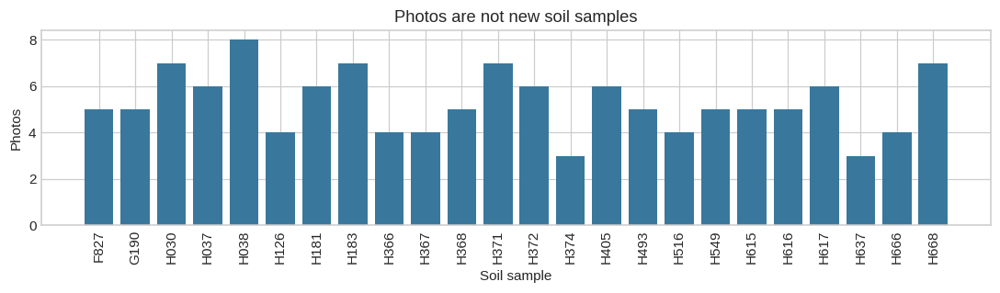

In [6]:
photo_counts = photos.groupby(["split", "sample_id"]).size().rename("photos").reset_index()
summary = photo_counts.groupby("split").agg(
    samples=("sample_id", "size"), photos=("photos", "sum"),
    min_photos=("photos", "min"), median_photos=("photos", "median"), max_photos=("photos", "max")
)
display(summary)
display(pd.crosstab(photos.device, photos.split))

train_counts = photo_counts.query("split == 'train'").sort_values("sample_id")
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(train_counts.sample_id, train_counts.photos, color="#39789c")
ax.set(xlabel="Soil sample", ylabel="Photos", title="Photos are not new soil samples")
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
plt.show()

## 3. Check the physical scale

PPM means pixels per mm. The scale table gives camera sizes.
Many train photos are smaller than these sizes.

We estimate new PPM from the resize ratio. We assume the photo was resized with no crop.
This is an estimate. Check it with a ruler before training.

photos  min_mp  max_mp  table_ppm  ppm_est  \
split device                                                                
test  iPhone 14                    14   12.19   12.19      13.94    13.94   
      iPhone 16                    21   24.47   24.47      19.52    19.52   
train Motorola Edge                69    1.15    1.15      11.49     4.60   
      Motorola Edge 60 Fusion       3    9.44    9.44      12.46    12.46   
      Samsung A52                  55    1.92    1.92      26.33     4.55   

                               short_side_mm  
split device                                  
test  iPhone 14                       216.90  
      iPhone 16                       219.41  
train Motorola Edge                   156.63  
      Motorola Edge 60 Fusion         184.84  
      Samsung A52                     263.51

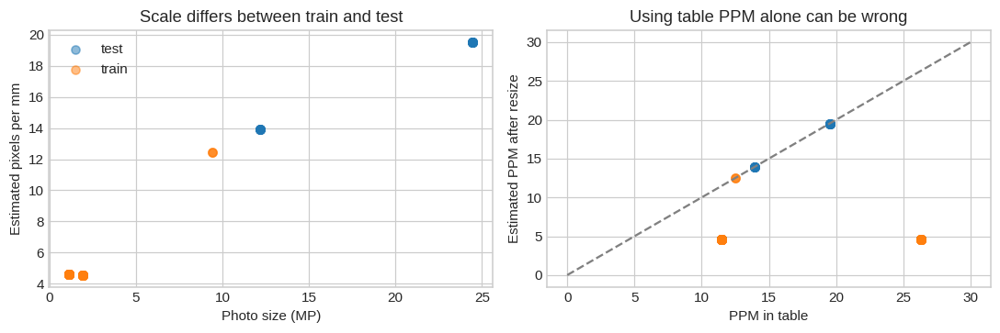

In [7]:
photos = photos.merge(
    scale.rename(columns={"phone": "device", "width": "camera_width", "height": "camera_height", "ppm": "camera_ppm"}),
    on="device", how="left", validate="many_to_one"
)
photos["resize_x"] = photos[["width", "height"]].max(axis=1) / photos[["camera_width", "camera_height"]].max(axis=1)
photos["resize_y"] = photos[["width", "height"]].min(axis=1) / photos[["camera_width", "camera_height"]].min(axis=1)
photos["ppm_est"] = photos.camera_ppm * (photos.resize_x + photos.resize_y) / 2
photos["megapixels"] = photos.width * photos.height / 1e6
photos["short_side_mm"] = photos[["width", "height"]].min(axis=1) / photos.ppm_est
assert (abs(photos.resize_x / photos.resize_y - 1) < 0.01).all()
assert photos.ppm_est.gt(0).all()

display(photos.groupby(["split", "device"]).agg(
    photos=("photo", "size"), min_mp=("megapixels", "min"), max_mp=("megapixels", "max"),
    table_ppm=("camera_ppm", "first"), ppm_est=("ppm_est", "median"),
    short_side_mm=("short_side_mm", "median")
).round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for split, group in photos.groupby("split"):
    axes[0].scatter(group.megapixels, group.ppm_est, label=split, alpha=0.5)
axes[0].set(xlabel="Photo size (MP)", ylabel="Estimated pixels per mm", title="Scale differs between train and test")
axes[0].legend()
for split, group in photos.groupby("split"):
    axes[1].scatter(group.camera_ppm, group.ppm_est, label=split, alpha=0.5)
axes[1].plot([0, 30], [0, 30], "--", color="grey")
axes[1].set(xlabel="PPM in table", ylabel="Estimated PPM after resize", title="Using table PPM alone can be wrong")
fig.tight_layout()
plt.show()

### 3.1. Resize, crop, and zoom

Resize changes the number of pixels in a file. It does not move the camera.
Crop keeps only part of the photo. Camera zoom changes the view when we take a photo.

Below, two outputs have the same pixel size. One keeps the full view. One keeps half the width and height.
Their PPM values differ. A matching shape alone cannot prove that no crop was used.
Making a small photo bigger cannot bring back lost detail.

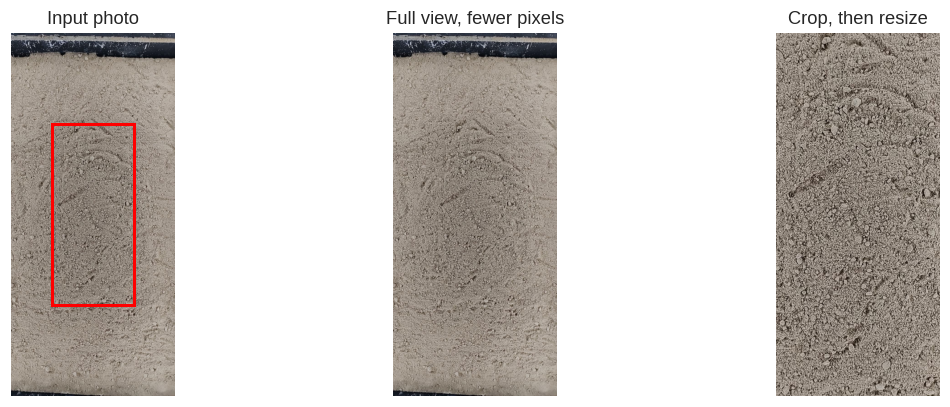

,operation,width_px,height_px,ppm_est
0,input,720,1600,4.597
1,full resize,288,640,1.839
2,"half-width crop, then resize",288,640,3.677


In [8]:
row = photos.query("split == 'train' and device == 'Motorola Edge'").iloc[0]
with Image.open(row.path) as source:
    full = ImageOps.exif_transpose(source).convert("RGB")
w, h = full.size
output_size = (round(w * 0.4), round(h * 0.4))
full_small = full.resize(output_size, Image.Resampling.LANCZOS)
crop_box = (w // 4, h // 4, 3 * w // 4, 3 * h // 4)
crop_small = full.crop(crop_box).resize(output_size, Image.Resampling.LANCZOS)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, image, title in zip(axes, [full, full_small, crop_small],
                          ["Input photo", "Full view, fewer pixels", "Crop, then resize"]):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
axes[0].add_patch(plt.Rectangle((w / 4, h / 4), w / 2, h / 2, fill=False, color="red", linewidth=2))
fig.tight_layout()
plt.show()
display(pd.DataFrame({
    "operation": ["input", "full resize", "half-width crop, then resize"],
    "width_px": [w, output_size[0], output_size[0]],
    "height_px": [h, output_size[1], output_size[1]],
    "ppm_est": [row.ppm_est, row.ppm_est * 0.4, row.ppm_est * 0.8],
}).round(3))

### 3.2. EXIF audit

We check all photos for camera, zoom, focal length, and editing fields.
A missing field means we do not know. It does not prove that the photo was not edited.
We save the full table as `exif_audit.csv`.

In [9]:
exif_tags = {"make": 271, "model": 272, "orientation": 274, "software": 305,
             "focal_mm": 37386, "zoom_ratio": 41988, "focal_35mm": 41989,
             "exif_width": 40962, "exif_height": 40963}
exif_rows = []
for row in photos.itertuples(index=False):
    with Image.open(row.path) as image:
        tags = image.getexif()
        tags = {**dict(tags), **tags.get_ifd(34665)}
    record = {"photo": row.photo, "split": row.split, "device": row.device,
              "size": f"{row.width} x {row.height}"}
    for name, tag in exif_tags.items():
        value = tags.get(tag)
        if isinstance(value, str):
            value = value.strip("\x00 ") or None
        elif value is not None:
            value = str(value)
        record[name] = value
    exif_rows.append(record)
exif_audit = pd.DataFrame(exif_rows)
exif_audit.to_csv(EXTRA_DIR / "exif_audit.csv", index=False)

exif_summary = exif_audit.groupby(["split", "device"]).agg(
    photos=("photo", "size"), sizes=("size", lambda x: "; ".join(sorted(x.unique()))),
    focal_mm=("focal_mm", lambda x: ", ".join(sorted(x.dropna().unique())) or "missing"),
    zoom=("zoom_ratio", lambda x: ", ".join(sorted(x.dropna().unique())) or "missing"),
    focal_35mm=("focal_35mm", lambda x: ", ".join(sorted(x.dropna().unique())) or "missing"),
    software=("software", lambda x: ", ".join(sorted(x.dropna().unique())) or "missing")
)
display(exif_summary)
display(exif_audit[list(exif_tags)].notna().sum().to_frame("photos_with_field"))

photos                   sizes  \
split device                                                    
test  iPhone 14                    14             4032 x 3024   
      iPhone 16                    21             5712 x 4284   
train Motorola Edge                69  1600 x 720; 720 x 1600   
      Motorola Edge 60 Fusion       3             4096 x 2304   
      Samsung A52                  55             1599 x 1200   

                                        focal_mm     zoom focal_35mm  \
split device                                                           
test  iPhone 14                              5.7  missing         26   
      iPhone 16                5.960000038146973  missing         26   
train Motorola Edge                      missing  missing    missing   
      Motorola Edge 60 Fusion               5.56      1.0         24   
      Samsung A52                        missing  missing    missing   

                                   software  
split device                                 
test  iPhone 14                17.5.1, 18.0  
      iPhone 16                      18.4.1  
train Motorola Edge                 missing  
      Motorola Edge 60 Fusion       missing  
      Samsung A52                   missing

,photos_with_field
make,38
model,38
orientation,38
software,35
focal_mm,38
zoom_ratio,3
focal_35mm,38
exif_width,38
exif_height,38


### 3.3. Photo overlap and rotation

We try to match grain patterns in photos of the same train sample.
SIFT finds points. RANSAC keeps points that agree with one flat-surface map.
We allow rotation. We keep matches spread across both images, not just one small spot.

A good match can show overlap. It cannot prove that two photos came from one original file.
The same tray can be photographed twice. Failed matches do not prove that there is no overlap.

In [10]:
# Use small views for this CPU check. Do not change the source photos.
sift = cv2.SIFT_create(nfeatures=1500)
matcher = cv2.BFMatcher()
views, features, view_ratios = {}, {}, {}
for row in photos.query("split == 'train'").itertuples(index=False):
    with Image.open(row.path) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")
        native_width = image.width
        image.thumbnail((900, 900))
    gray = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2GRAY)
    views[row.photo] = gray
    view_ratios[row.photo] = image.width / native_width
    features[row.photo] = sift.detectAndCompute(gray, None)

pair_rows, pair_maps = [], {}
for sample_id, group in photos.query("split == 'train'").groupby("sample_id"):
    for a, b in combinations(group.to_dict("records"), 2):
        ka, da = features[a["photo"]]
        kb, db = features[b["photo"]]
        if da is None or db is None:
            continue
        forward = matcher.knnMatch(da, db, k=2)
        backward = matcher.knnMatch(db, da, k=2)
        reverse = {}
        for pair in backward:
            if len(pair) == 2 and pair[0].distance < 0.7 * pair[1].distance:
                reverse[pair[0].queryIdx] = pair[0].trainIdx
        good = []
        for pair in forward:
            if len(pair) != 2:
                continue
            m, n = pair
            if m.distance < 0.7 * n.distance and reverse.get(m.trainIdx) == m.queryIdx:
                good.append(m)
        if len(good) < 12:
            continue
        pa = np.float32([ka[m.queryIdx].pt for m in good])
        pb = np.float32([kb[m.trainIdx].pt for m in good])
        H, mask = cv2.findHomography(pa, pb, cv2.RANSAC, 3.0)
        if H is None:
            continue
        keep = mask.ravel().astype(bool)
        ia, ib = pa[keep], pb[keep]
        spread_a = cv2.contourArea(cv2.convexHull(ia)) / views[a["photo"]].size
        spread_b = cv2.contourArea(cv2.convexHull(ib)) / views[b["photo"]].size
        strong = keep.sum() >= 25 and keep.mean() >= 0.4 and min(spread_a, spread_b) >= 0.05
        warped = cv2.perspectiveTransform(ia[:, None, :], H)[:, 0, :]
        error_px = np.linalg.norm(warped - ib, axis=1)
        # Compare the same two visible points. This is not a known tray width.
        distance = np.linalg.norm(ia[:, None, :] - ia[None, :, :], axis=-1)
        i, j = np.unravel_index(distance.argmax(), distance.shape)
        mm_a = np.linalg.norm(ia[i] - ia[j]) / view_ratios[a["photo"]] / a["ppm_est"]
        mm_b = np.linalg.norm(ib[i] - ib[j]) / view_ratios[b["photo"]] / b["ppm_est"]
        key = len(pair_rows)
        pair_rows.append({"sample_id": sample_id, "photo_a": a["photo"], "photo_b": b["photo"],
                          "device_a": a["device"], "device_b": b["device"], "matches": len(good),
                          "inliers": int(keep.sum()), "inlier_ratio": keep.mean(),
                          "spread_a": spread_a, "spread_b": spread_b, "median_error_px": np.median(error_px),
                          "same_segment_mm_a": mm_a, "same_segment_mm_b": mm_b,
                          "segment_ratio_b_to_a": mm_b / mm_a, "strong": strong})
        pair_maps[key] = (H, ia, ib)

pairs = pd.DataFrame(pair_rows)
strong_pairs = pairs.query("strong").copy() if len(pairs) else pairs.copy()
pairs.to_csv(EXTRA_DIR / "photo_matches.csv", index=False)
print("All within-sample pairs checked:", sum(len(g) * (len(g) - 1) // 2 for _, g in photos.query("split == 'train'").groupby("sample_id")))
print("Pairs with at least 12 mutual matches:", len(pairs))
print("Pairs that pass the stronger geometry check:", len(strong_pairs))
if len(strong_pairs):
    display(strong_pairs.sort_values("inliers", ascending=False).head(10)[
        ["sample_id", "photo_a", "photo_b", "inliers", "inlier_ratio", "median_error_px", "segment_ratio_b_to_a"]
    ].round(3))

All within-sample pairs checked: 293
Pairs with at least 12 mutual matches: 230
Pairs that pass the stronger geometry check: 133


,sample_id,photo_a,photo_b,inliers,inlier_ratio,median_error_px,segment_ratio_b_to_a
159,H516,Motorola_Edge_H516_01.jpg,Samsung_A52_H516_01.jpg,836,1.000,0.471,1.011
124,H372,Motorola_Edge_H372_02.jpg,Samsung_A52_H372_01.jpg,794,1.000,0.583,1.012
87,H181,Motorola_Edge_H181_04.jpg,Samsung_A52_H181_02.jpg,762,1.000,0.639,1.010
111,H368,Motorola_Edge_H368_04.jpg,Samsung_A52_H368_01.jpg,760,0.996,0.478,1.016
113,H371,Motorola_Edge_H371_01.jpg,Samsung_A52_H371_01.jpg,755,1.000,0.577,1.012
105,H367,Motorola_Edge_H367_03.jpg,Samsung_A52_H367_01.jpg,747,1.000,0.428,1.016
83,H181,Motorola_Edge_H181_02.jpg,Samsung_A52_H181_01.jpg,743,1.000,0.518,1.012
173,H615,Motorola_Edge_H615_02.jpg,Samsung_A52_H615_02.jpg,718,1.000,0.698,1.016
143,H405,Motorola_Edge_H405_03.jpg,Samsung_A52_H405_03.jpg,702,1.000,0.555,1.011
139,H405,Motorola_Edge_H405_02.jpg,Samsung_A52_H405_02.jpg,698,1.000,0.592,1.012


### 3.4. Align one pair

The middle view puts image A into image B's view. The last view shows B.
Cyan lines mark A's mapped border. Red dots are the same points in both views.
Missing areas stay black. We do not fill them with made-up image detail.

The two-point length check uses estimated PPM. A difference may come from scale, crop, distance, or camera angle.
We do not know the real tray width, so we do not use a guessed tray edge as a ruler.

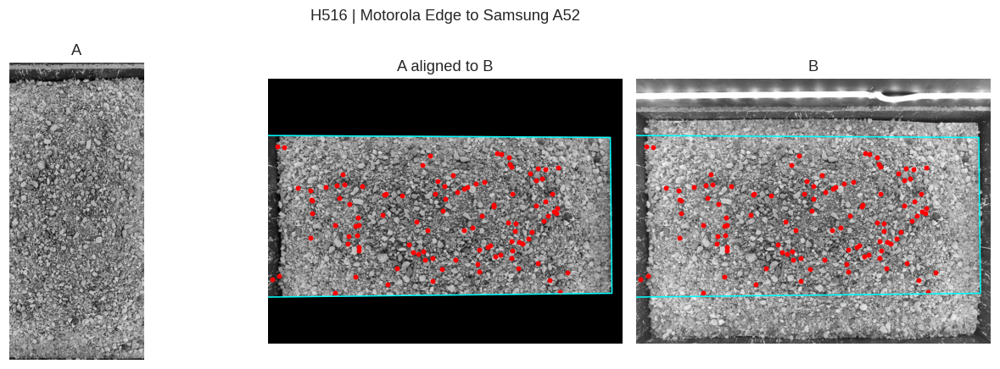

Fraction of B covered by A: 0.566
Gray pixel MAE (0 to 255): 25.335 | correlation: 0.853
The images share a surface patch. These values do not prove that one file was cut from the other.


,estimate
same_segment_mm_a,358.358063
same_segment_mm_b,362.279663
segment_ratio_b_to_a,1.010943


count  median    min    max
device_a      device_b                                  
Motorola Edge Motorola Edge     22   0.999  0.991  1.002
              Samsung A52       67   1.012  1.002  1.037
Samsung A52   Samsung A52       44   1.000  0.995  1.004

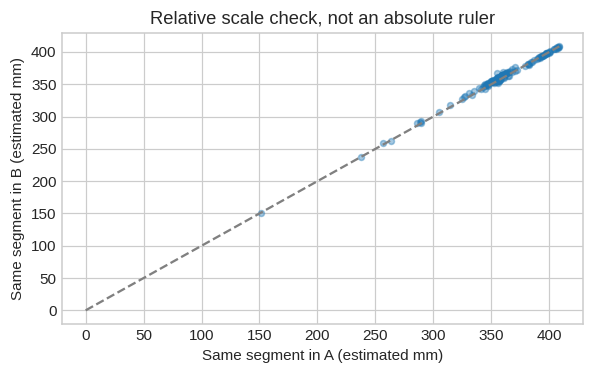

In [11]:
if len(strong_pairs):
    cross_camera = strong_pairs.query("device_a != device_b")
    candidates = cross_camera if len(cross_camera) else strong_pairs
    best = candidates.sort_values("inliers", ascending=False).iloc[0]
    H, ia, ib = pair_maps[best.name]
    va, vb = views[best.photo_a], views[best.photo_b]
    aligned = cv2.warpPerspective(va, H, (vb.shape[1], vb.shape[0]))
    corners = np.float32([[0, 0], [va.shape[1]-1, 0], [va.shape[1]-1, va.shape[0]-1], [0, va.shape[0]-1]])
    border = cv2.perspectiveTransform(corners[:, None, :], H)[:, 0, :]
    border = np.vstack([border, border[0]])
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, image, title in zip(axes, [va, aligned, vb], ["A", "A aligned to B", "B"]):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    for ax in axes[1:]:
        ax.plot(border[:, 0], border[:, 1], color="cyan", linewidth=1)
        ax.scatter(ib[::8, 0], ib[::8, 1], s=8, color="red")
        ax.set_xlim(0, vb.shape[1]); ax.set_ylim(vb.shape[0], 0)
    fig.suptitle(best.sample_id + " | " + best.device_a + " to " + best.device_b)
    fig.tight_layout()
    plt.show()
    mask_image = cv2.warpPerspective(np.ones_like(va)*255, H, (vb.shape[1], vb.shape[0]))
    inside = cv2.erode(mask_image, np.ones((9, 9), np.uint8)) > 250
    pixel_mae = np.abs(aligned[inside].astype(float)-vb[inside].astype(float)).mean()
    pixel_corr = np.corrcoef(aligned[inside], vb[inside])[0,1]
    print(f"Fraction of B covered by A: {inside.mean():.3f}")
    print(f"Gray pixel MAE (0 to 255): {pixel_mae:.3f} | correlation: {pixel_corr:.3f}")
    print("The images share a surface patch. These values do not prove that one file was cut from the other.")
    display(best[["same_segment_mm_a", "same_segment_mm_b", "segment_ratio_b_to_a"]].to_frame("estimate"))
    display(strong_pairs.groupby(["device_a", "device_b"]).segment_ratio_b_to_a.agg(["count", "median", "min", "max"]).round(3))
    fig, ax = plt.subplots(figsize=(5.5, 3.5))
    ax.scatter(strong_pairs.same_segment_mm_a, strong_pairs.same_segment_mm_b, alpha=0.4, s=15)
    upper = max(strong_pairs.same_segment_mm_a.max(), strong_pairs.same_segment_mm_b.max())
    ax.plot([0, upper], [0, upper], "--", color="gray")
    ax.set(xlabel="Same segment in A (estimated mm)", ylabel="Same segment in B (estimated mm)", title="Relative scale check, not an absolute ruler")
    fig.tight_layout()
    plt.show()
else:
    print("No pair passes the stronger check. We cannot make a useful alignment from these matches.")

### 3.5. See all photos of six samples

Each page shows all photos of one train sample. We include soils with only one camera too.
The mm values are estimates. Small views here are for display only.

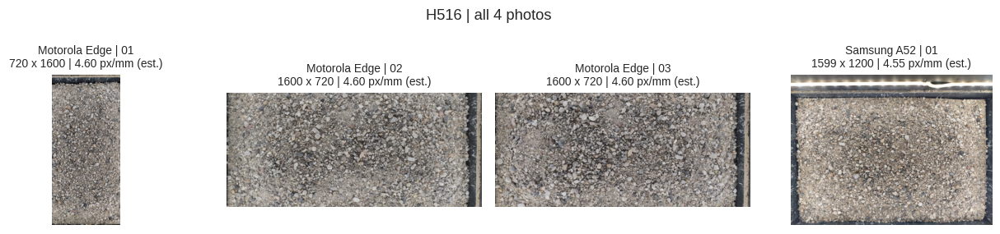

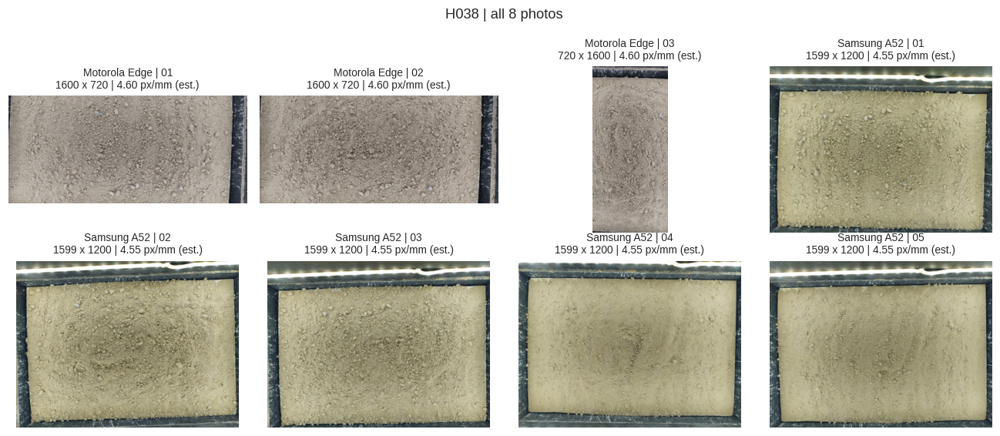

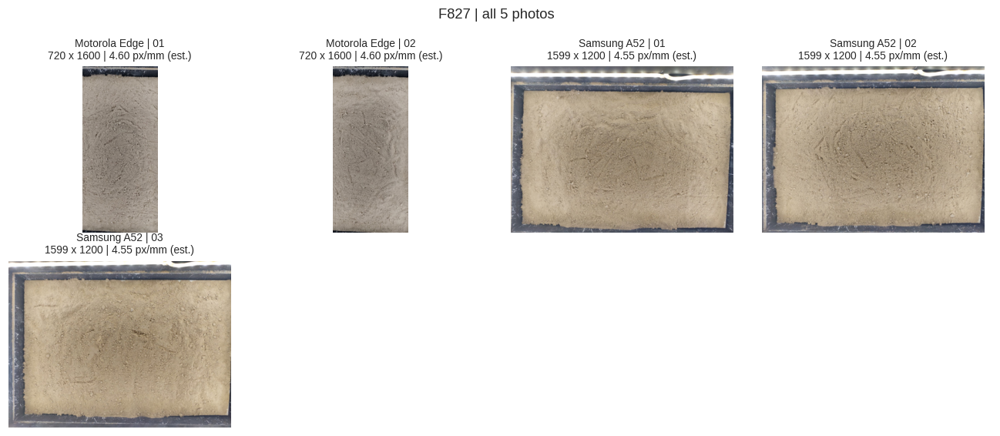

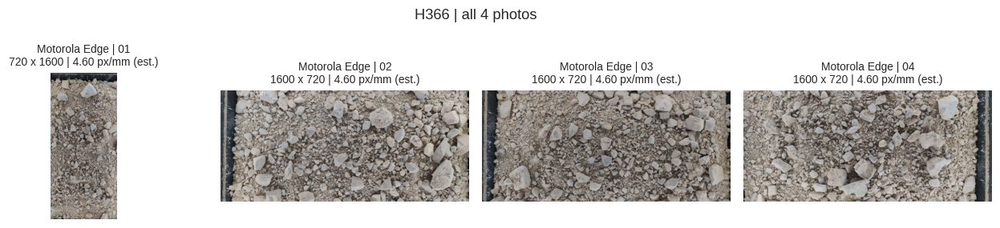

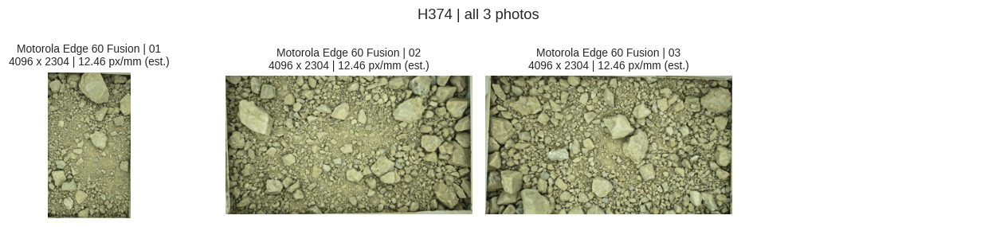

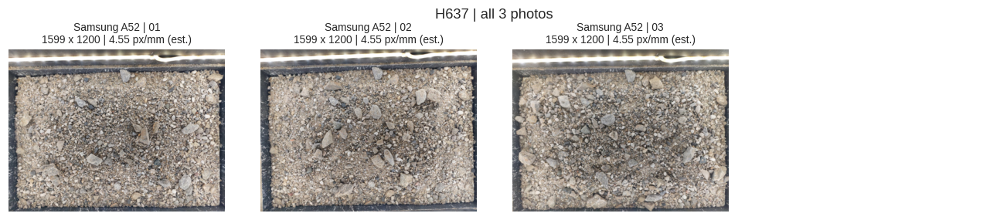

In [12]:
train_view = photos.query("split == 'train'")
soil_order = labels.sort_values("0.063").sample_id.to_list()
audit_samples = [soil_order[0], soil_order[len(soil_order)//2], soil_order[-1]]
single_camera = train_view.groupby("sample_id").device.nunique()
audit_samples += single_camera[single_camera == 1].index.to_list()
audit_samples += [sample for sample in soil_order if sample not in audit_samples]
audit_samples = list(dict.fromkeys(audit_samples))[:6]
for sample_id in audit_samples:
    group = train_view.query("sample_id == @sample_id").sort_values(["device", "photo"])
    n_rows = (len(group) + 3) // 4
    fig, axes = plt.subplots(n_rows, 4, figsize=(12, 2.6 * n_rows), squeeze=False)
    for ax, row in zip(axes.flat, group.itertuples(index=False)):
        with Image.open(row.path) as source:
            image = ImageOps.exif_transpose(source).convert("RGB")
            image.thumbnail((400, 300))
        ax.imshow(image)
        ax.set_title(row.device + " | " + Path(row.photo).stem.rsplit("_", 1)[-1] +
                     f"\n{row.width} x {row.height} | {row.ppm_est:.2f} px/mm (est.)", fontsize=9)
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(sample_id + " | all " + str(len(group)) + " photos")
    fig.tight_layout()
    plt.show()

### 3.6. What the scale checks can tell us

The photo sizes fit a full-image resize, but this does not prove it.
A crop with the same shape can give the same file size.
Camera PPM can also change with distance or zoom.

A source photo before editing, a known ruler, or the real tray size would make a stronger test.
Until then, `ppm_est` stays an estimate for every device.

In [13]:
scale_evidence = photos.groupby(["split", "device"]).agg(
    photos=("photo", "size"), table_ppm=("camera_ppm", "first"), estimated_ppm=("ppm_est", "median"),
    resize_ratio=("resize_x", "median")
).reset_index()
scale_evidence["no_crop_proved"] = False
scale_evidence["absolute_scale_verified"] = False
scale_evidence["known_length_in_files_mm"] = np.nan
display(scale_evidence.round(3))
scale_evidence.to_csv(EXTRA_DIR / "scale_evidence.csv", index=False)

,split,device,photos,table_ppm,estimated_ppm,resize_ratio,no_crop_proved,absolute_scale_verified,known_length_in_files_mm
0,test,iPhone 14,14,13.942,13.942,1.000,False,False,NaN
1,test,iPhone 16,21,19.525,19.525,1.000,False,False,NaN
2,train,Motorola Edge,69,11.492,4.597,0.400,False,False,NaN
3,train,Motorola Edge 60 Fusion,3,12.465,12.465,1.000,False,False,NaN
4,train,Samsung A52,55,26.330,4.554,0.173,False,False,NaN


### 3.7. Which grains are large enough to see?

We multiply grain size by estimated PPM. The table shows grain size in pixels.
1, 3, and 5 pixels are rough guides, not hard limits of a camera.
A small grain may still affect texture even when we cannot see its shape.

,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
test | iPhone 14,0.028,0.088,0.279,0.878,2.788,8.783,27.884,87.835,278.840,878.346,2788.400
test | iPhone 16,0.039,0.123,0.390,1.230,3.905,12.301,39.050,123.008,390.500,1230.075,3905.000
train | Motorola Edge,0.009,0.029,0.092,0.290,0.919,2.896,9.194,28.960,91.936,289.598,919.360
train | Motorola Edge 60 Fusion,0.025,0.079,0.249,0.785,2.493,7.853,24.930,78.530,249.300,785.295,2493.000
train | Samsung A52,0.009,0.029,0.091,0.287,0.911,2.869,9.108,28.690,91.079,286.898,910.788


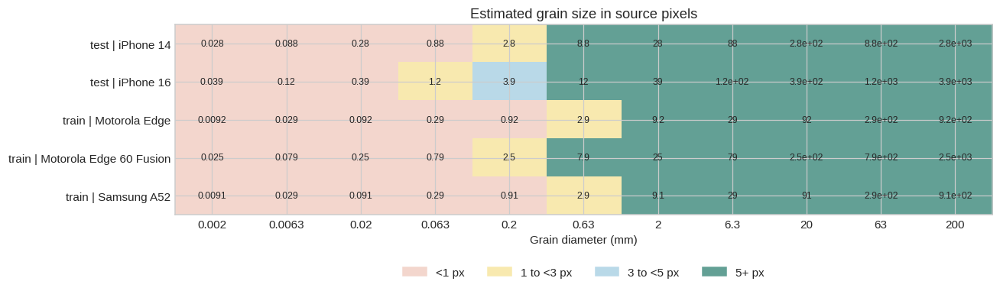

In [14]:
resolution = photos.groupby(["split", "device"]).ppm_est.median()
resolution.index = [split + " | " + device for split, device in resolution.index]
pixel_sizes = pd.DataFrame(resolution.to_numpy()[:, None] * sieves, index=resolution.index, columns=targets)
display(pixel_sizes.round(3))
colors = ListedColormap(["#f3d6cd", "#f8e9af", "#b9d9e8", "#63a095"])
bounds = BoundaryNorm([0, 1, 3, 5, 1e9], colors.N)
fig, ax = plt.subplots(figsize=(12, 3.7))
image = ax.imshow(pixel_sizes.to_numpy(), cmap=colors, norm=bounds, aspect="auto")
for i, row in enumerate(pixel_sizes.to_numpy()):
    for j, value in enumerate(row):
        ax.text(j, i, f"{value:.2g}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(targets)), targets)
ax.set_yticks(range(len(pixel_sizes)), pixel_sizes.index)
ax.set(xlabel="Grain diameter (mm)", title="Estimated grain size in source pixels")
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in colors.colors]
ax.legend(handles, ["<1 px", "1 to <3 px", "3 to <5 px", "5+ px"], loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4)
fig.tight_layout()
plt.show()
resolution.to_frame("ppm_est").assign(three_pixel_grain_mm=3/resolution).to_csv(EXTRA_DIR / "source_resolution.csv")

## 4. Look at fine and coarse soils

The curves go up from 0 to 100. A curve near the left has more small grains.
We use three simple groups to help make balanced folds. These are not full soil classes.

,samples,median_fines_pct
soil_group,,
fine,7,69.76
gravel,11,8.69
sand,6,31.25


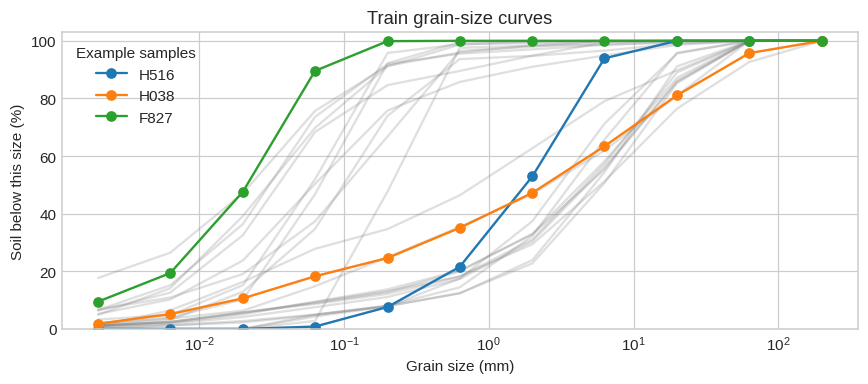

In [15]:
labels["soil_group"] = np.where(labels["0.063"] >= 50, "fine", np.where(labels["2"] >= 50, "sand", "gravel"))
display(labels.groupby("soil_group").agg(samples=("sample_id", "size"), median_fines_pct=("0.063", "median")).round(2))

order = labels.sort_values("0.063").index.to_numpy()
example_indices = order[[0, len(order) // 2, -1]]
example_ids = labels.loc[example_indices, "sample_id"].tolist()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.semilogx(sieves, y.T, color="grey", alpha=0.25)
for index in example_indices:
    ax.semilogx(sieves, y[index], marker="o", label=labels.loc[index, "sample_id"])
ax.set(xlabel="Grain size (mm)", ylabel="Soil below this size (%)", ylim=(0, 103), title="Train grain-size curves")
ax.legend(title="Example samples")
fig.tight_layout()
plt.show()

### 4.1. Why 0.063 mm and 2 mm?

[ISO 14688-1](https://standards.iteh.ai/catalog/standards/iso/04a258c5-a699-4291-9fa5-4835c0206a9f/iso-14688-1-2017) uses these size limits for soil particles.
0.063 mm separates silt-sized and sand-sized particles. 2 mm separates sand-sized and gravel-sized particles.

Our 50% rule puts the median grain size in a range. It is only a way to balance folds.
It does not always name the largest mass part. For example, 40% fines, 20% sand, and 40% gravel gives group `sand`.
This is not a full soil class. We do not have plasticity tests.

,fines_pct,sand_pct,gravel_plus_pct
sample_id,,,
F827,89.56,10.44,0.00
G190,50.31,40.68,9.01
H030,37.32,60.63,2.05
H037,27.80,34.91,37.28
H038,18.28,28.96,52.77
H126,68.36,26.49,5.15
H181,4.30,33.11,62.59
H183,4.95,27.33,67.72
H366,9.48,23.33,67.18


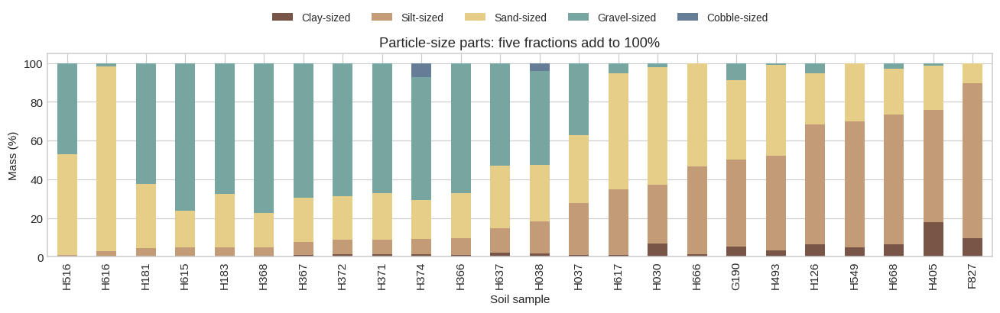

In [16]:
c = labels.set_index("sample_id")
composition = pd.DataFrame({
    "Clay-sized": c["0.002"],
    "Silt-sized": c["0.063"] - c["0.002"],
    "Sand-sized": c["2"] - c["0.063"],
    "Gravel-sized": c["63"] - c["2"],
    "Cobble-sized": 100 - c["63"],
})
assert np.allclose(composition.sum(axis=1), 100)
assert (composition >= -1e-6).all().all()
fractions = pd.DataFrame({"fines_pct": c["0.063"], "sand_pct": c["2"] - c["0.063"], "gravel_plus_pct": 100-c["2"]})
display(fractions.round(2))
composition.loc[labels.sort_values("0.063").sample_id].plot.bar(
    stacked=True, figsize=(12, 4), color=["#795548", "#c39b77", "#e6ce89", "#77a6a1", "#657d96"]
)
plt.ylabel("Mass (%)")
plt.xlabel("Soil sample")
plt.title("Particle-size parts: five fractions add to 100%")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, 1.25), ncol=5, fontsize=9)
plt.tight_layout()
plt.show()
composition.to_csv(EXTRA_DIR / "grain_composition.csv")

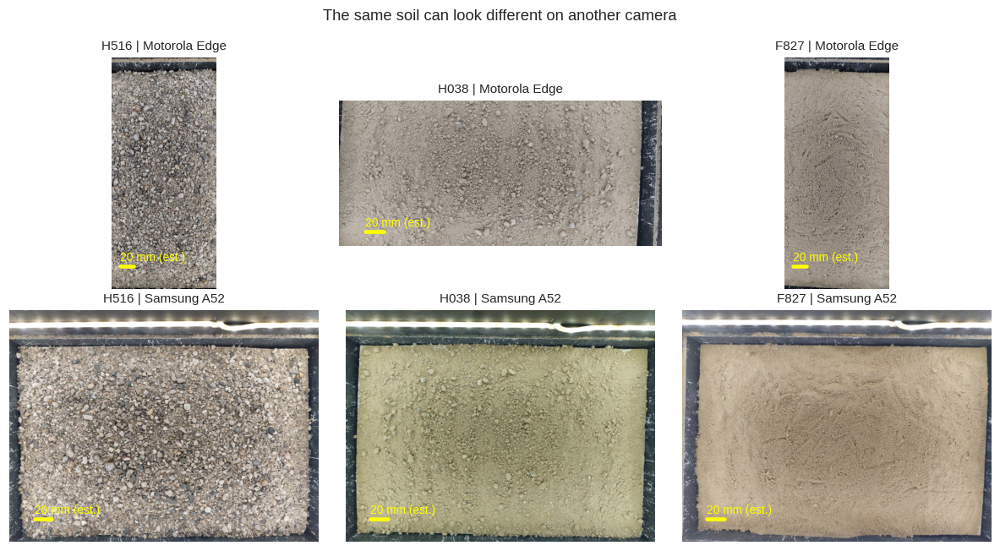

In [17]:
# Show up to two cameras for each example soil.
examples = []
for sample_id in example_ids:
    group = photos.query("split == 'train' and sample_id == @sample_id")
    examples.extend(group.drop_duplicates("device").head(2).to_dict("records"))

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, row in zip(axes.T.flat, examples):
    with Image.open(row["path"]) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")
        full_width = image.width
        image.thumbnail((640, 480))
    ax.imshow(image)
    bar_px = 20 * row["ppm_est"] * image.width / full_width
    x, y_bar = image.width * 0.08, image.height * 0.9
    ax.plot([x, x + bar_px], [y_bar, y_bar], color="yellow", linewidth=3)
    ax.text(x, y_bar - 10, "20 mm (est.)", color="yellow", fontsize=9)
    ax.set_title(row["sample_id"] + " | " + row["device"], fontsize=10)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("The same soil can look different on another camera")
fig.tight_layout()
plt.show()

## 5. Useful grain sizes

D10, D50, and D60 are sizes where 10%, 50%, and 60% of soil pass.
We find them between the known points on a log-size axis.
If a size is below the first point, we leave it empty. We do not guess it.

In [18]:
def grain_size(curve, percent):
    if percent < curve[0] or percent > curve[-1]:
        return np.nan
    right = np.searchsorted(curve, percent, side="left")
    if right == 0:
        return sieves[0]
    left = right - 1
    fraction = (percent - curve[left]) / (curve[right] - curve[left])
    return 10 ** (log_sieves[left] + fraction * (log_sieves[right] - log_sieves[left]))

grain_sizes = labels[["sample_id", "soil_group"]].copy()
for percent in [10, 50, 60]:
    grain_sizes[f"D{percent}_mm"] = [grain_size(curve, percent) for curve in y]
display(grain_sizes.groupby("soil_group")[["D10_mm", "D50_mm", "D60_mm"]].median().round(3))
print("Values below the measured size range:")
display(grain_sizes[["D10_mm", "D50_mm", "D60_mm"]].isna().sum().to_frame("count"))

,D10_mm,D50_mm,D60_mm
soil_group,,,
fine,0.004,0.030,0.044
gravel,0.097,4.585,6.961
sand,0.017,0.157,0.209


Values below the measured size range:


,count
D10_mm,1
D50_mm,0
D60_mm,0


### 5.1. Target values and flat tails

The 11 targets are linked. Larger sieve values cannot be lower.
The last target is always 100. Its correlation is not defined, so we leave it out of that plot.
These plots describe the labels. They do not test an image model.

,min,median,max,at_100_pct
0.002,0.00,1.18,17.71,0.00
0.0063,0.00,3.36,26.46,0.00
0.02,0.00,8.27,47.63,0.00
0.063,0.82,16.55,89.56,0.00
0.2,7.63,29.78,99.90,0.00
0.63,12.35,40.88,99.99,0.00
2,22.76,57.83,100.00,4.17
6.3,50.68,86.49,100.00,12.50
20,76.49,97.21,100.00,33.33
63,92.64,100.00,100.00,91.67


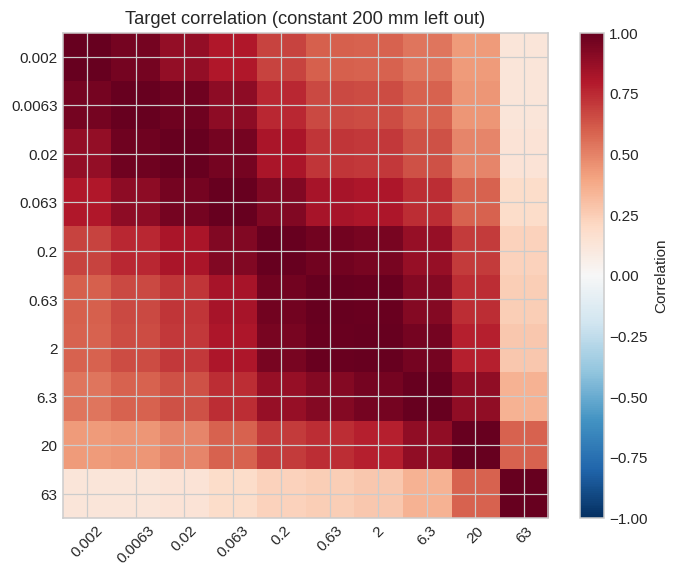

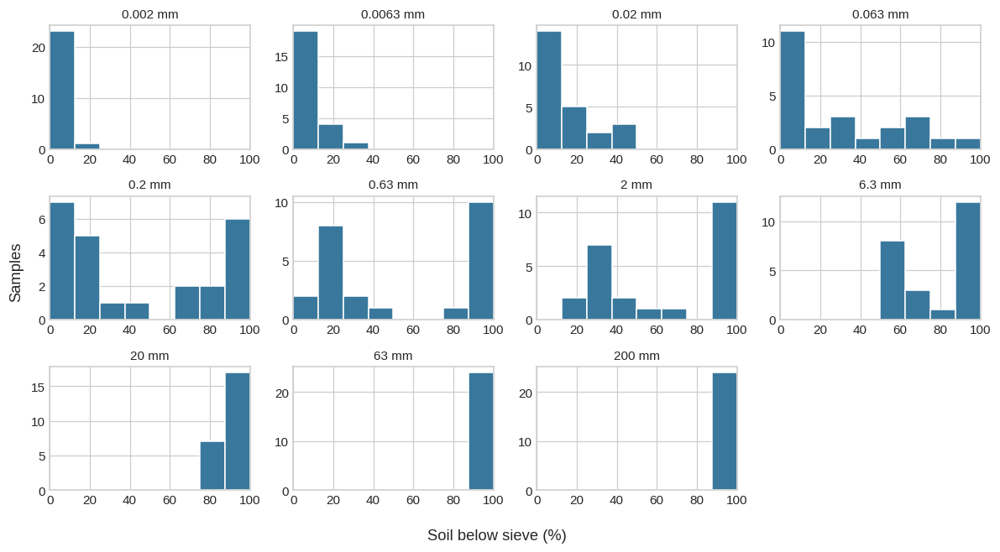

In [19]:
target_summary = labels[targets].agg(["min", "median", "max"]).T
target_summary["at_100_pct"] = np.isclose(y, 100).mean(axis=0) * 100
display(target_summary.round(2))
variable_targets = labels[targets].columns[labels[targets].std() > 1e-9]
corr = labels[variable_targets].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.3))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(corr)), corr.columns, rotation=45)
ax.set_yticks(range(len(corr)), corr.index)
ax.set_title("Target correlation (constant 200 mm left out)")
fig.colorbar(image, ax=ax, label="Correlation")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(11, 6))
for ax, column in zip(axes.flat, targets):
    ax.hist(labels[column], bins=np.linspace(0, 100, 9), color="#39789c", edgecolor="white")
    ax.set_title(column + " mm", fontsize=10)
    ax.set_xlim(0, 100)
for ax in axes.flat[len(targets):]:
    ax.axis("off")
fig.supxlabel("Soil below sieve (%)")
fig.supylabel("Samples")
fig.tight_layout()
plt.show()

### 5.2. How many curve values carry most of the change?

PCA finds directions of change in the 11 values. Here it only describes all train labels.
This is not a CV score. A later model must fit PCA on each fold's train labels only.
A short code for a curve may help, but it may also lose rare soil types.

,components,total_variance_pct
0,1,91.43
1,2,97.63
2,3,99.01
3,4,99.66
4,5,99.85
5,6,99.95
6,7,99.97
7,8,99.99
8,9,100.00
9,10,100.00


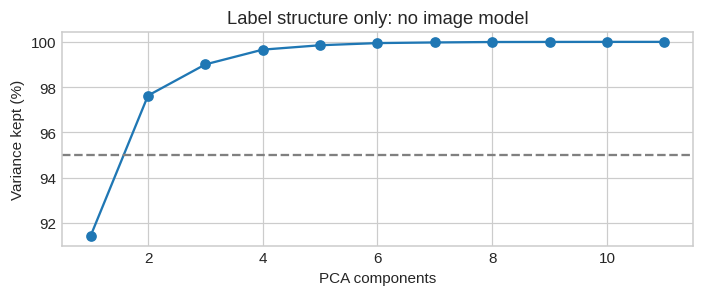

In [20]:
pca = PCA().fit(y)
variance = np.cumsum(pca.explained_variance_ratio_)
display(pd.DataFrame({"components": np.arange(1, len(variance)+1), "total_variance_pct": 100*variance}).round(2))
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(np.arange(1, len(variance)+1), 100*variance, marker="o")
ax.axhline(95, color="gray", linestyle="--")
ax.set(xlabel="PCA components", ylabel="Variance kept (%)", title="Label structure only: no image model")
fig.tight_layout()
plt.show()

## 6. Check the competition score

The score adds curve errors over ten log-size intervals. It uses the left point of each interval.
Lower is better. We use percent values, not values from 0 to 1.
The last point has no interval weight, but a valid curve must end at 100.

In [21]:
log_widths = np.diff(log_sieves)

def emd_per_sample(true, pred):
    true = np.asarray(true, dtype=float)
    pred = np.asarray(pred, dtype=float)
    assert true.shape == pred.shape and true.shape[-1] == len(sieves)
    return (np.abs(true - pred)[..., :-1] * log_widths).sum(axis=-1)

fine_curve = np.full(11, 100.0)
coarse_curve = np.r_[np.zeros(10), 100.0]
assert np.isclose(emd_per_sample(fine_curve, fine_curve), 0)
assert np.isclose(emd_per_sample(fine_curve, coarse_curve), 500)

one_error = coarse_curve.copy()
one_error[0] = 10
assert np.isclose(emd_per_sample(coarse_curve, one_error), 10 * log_widths[0])

# The last point is checked as a rule, not as an interval in the score.
wrong_end = fine_curve.copy()
wrong_end[-1] = 80
assert emd_per_sample(fine_curve, wrong_end) == 0
print("Metric checks passed: zero error, maximum 500, interval weight, and last point.")
print("A low score alone does not prove that a curve is valid.")

Metric checks passed: zero error, maximum 500, interval weight, and last point.
A low score alone does not prove that a curve is valid.


## 7. What can a scale error cost?

This is a curve test, not a model test. We make all grains 2x larger or smaller.
We shift each curve on the size axis. We use 0 and 100 outside the known range.
We set the last point to 100 so the new curve is valid.

,size_factor,mean_EMD,min_EMD,max_EMD
0,0.5,29.185,24.773,30.103
1,1.0,0.000,0.000,0.000
2,2.0,30.566,28.119,33.606


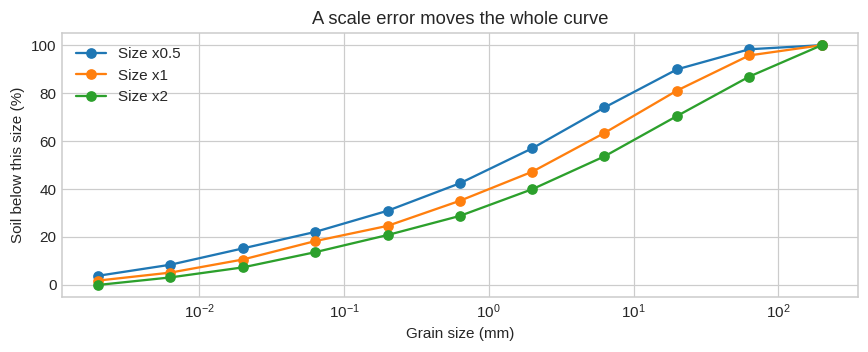

In [22]:
scale_scores = []
shifted_curves = {}
for factor in [0.5, 1.0, 2.0]:
    pred = np.array([np.interp(np.log10(sieves / factor), log_sieves, curve, left=0, right=100) for curve in y])
    pred[:, -1] = 100
    shifted_curves[factor] = pred
    error = emd_per_sample(y, pred)
    scale_scores.append({"size_factor": factor, "mean_EMD": error.mean(), "min_EMD": error.min(), "max_EMD": error.max()})
display(pd.DataFrame(scale_scores).round(3))

index = example_indices[1]
fig, ax = plt.subplots(figsize=(8, 3.3))
for factor, pred in shifted_curves.items():
    ax.semilogx(sieves, pred[index], marker="o", label=f"Size x{factor:g}")
ax.set(xlabel="Grain size (mm)", ylabel="Soil below this size (%)", title="A scale error moves the whole curve")
ax.legend()
fig.tight_layout()
plt.show()

## 8. Make safe folds

We split soil samples, then give each photo its sample fold.
No sample can be in train and validation at the same time.
We keep the same four folds for all later models.

In [23]:
N_FOLDS = 4
folds = labels[["sample_id", "soil_group"]].copy()
folds["fold"] = -1
splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
assert folds.soil_group.value_counts().min() >= N_FOLDS
for fold, (_, valid_index) in enumerate(splitter.split(folds, folds.soil_group)):
    folds.loc[valid_index, "fold"] = fold

train_photos = photos.query("split == 'train'").merge(folds[["sample_id", "fold"]], on="sample_id", validate="many_to_one")
for fold in range(N_FOLDS):
    train_samples = set(train_photos.query("fold != @fold").sample_id)
    valid_samples = set(train_photos.query("fold == @fold").sample_id)
    assert train_samples.isdisjoint(valid_samples)
assert train_photos.groupby("sample_id").fold.nunique().eq(1).all()

# Show why a random photo split is unsafe.
train_part, valid_part = train_test_split(train_photos, test_size=0.25, random_state=SEED)
leaked = set(train_part.sample_id) & set(valid_part.sample_id)
print("Shared soil samples in a random photo split:", len(leaked))
print("Shared soil samples in our folds: 0")
display(pd.crosstab(folds.fold, folds.soil_group))
folds.to_csv(WORK_DIR / "sample_folds.csv", index=False)
train_photos.to_csv(WORK_DIR / "photo_folds.csv", index=False)

Shared soil samples in a random photo split: 19
Shared soil samples in our folds: 0


soil_group,fine,gravel,sand
fold,,,
0,2,2,2
1,2,3,1
2,2,3,1
3,1,3,2


## 9. Start with simple baselines

These baselines do not use images. Mean and median use only the train samples of each fold.
We score one curve per soil sample. More photos do not give a sample more weight.

In [24]:
oof = {name: np.zeros_like(y) for name in ["equal_bins", "train_mean", "train_median"]}
fold_id = folds.fold.to_numpy()
for fold in range(N_FOLDS):
    train_index = fold_id != fold
    valid_index = fold_id == fold
    oof["equal_bins"][valid_index] = np.arange(1, 12) / 11 * 100
    oof["train_mean"][valid_index] = y[train_index].mean(axis=0)
    oof["train_median"][valid_index] = np.median(y[train_index], axis=0)

fold_scores = []
for name, pred in oof.items():
    assert np.all(np.diff(pred, axis=1) >= -1e-6)
    assert np.allclose(pred[:, -1], 100)
    error = emd_per_sample(y, pred)
    for fold in range(N_FOLDS):
        fold_scores.append({"baseline": name, "fold": fold, "EMD": error[fold_id == fold].mean()})
    saved = pd.DataFrame(pred, columns=targets)
    saved.insert(0, "sample_id", labels.sample_id)
    saved.to_csv(WORK_DIR / f"oof_{name}.csv", index=False)

fold_scores = pd.DataFrame(fold_scores)
display(fold_scores.pivot(index="fold", columns="baseline", values="EMD").round(3))
display(fold_scores.groupby("baseline").EMD.agg(["mean", "std"]).round(3))
print("Std is the spread across four folds. It is not a confidence interval.")

baseline,equal_bins,train_mean,train_median
fold,,,
0,88.550,74.140,75.810
1,109.821,96.696,94.285
2,101.950,86.277,86.137
3,107.773,88.731,84.621


,mean,std
baseline,,
equal_bins,102.023,9.581
train_mean,86.461,9.341
train_median,85.213,7.570


Std is the spread across four folds. It is not a confidence interval.


### 9.1. Leave one sample out

For an absolute-error score, the train median is the best constant fit to the train labels.
EMD adds absolute errors with positive weights. This is why median is a useful baseline.
It does not prove that median will win on new data.

Now we leave out one soil sample at a time. We also show sample bootstrap intervals for the saved OOF errors.
These intervals keep predictions fixed. They do not include all uncertainty from fitting or choosing folds.

LOOCV uses different train sets from four-fold CV. It checks split sensitivity.
Keep the original four folds to compare later image models.

In [25]:
loo_pred = np.array([np.median(np.delete(y, i, axis=0), axis=0) for i in range(len(y))])
loo_error = emd_per_sample(y, loo_pred)
loo_results = pd.DataFrame({"sample_id": labels.sample_id, "soil_group": labels.soil_group, "EMD": loo_error})
display(loo_results.sort_values("EMD", ascending=False).round(3))
loo_results.to_csv(EXTRA_DIR / "loo_median_errors.csv", index=False)
loo_saved = pd.DataFrame(loo_pred, columns=targets)
loo_saved.insert(0, "sample_id", labels.sample_id)
loo_saved.to_csv(EXTRA_DIR / "oof_loo_median.csv", index=False)

rng = np.random.default_rng(SEED)
bootstrap_index = rng.integers(0, len(y), size=(5000, len(y)))
bootstrap_rows = []
for name, predictions in {**oof, "loo_median": loo_pred}.items():
    errors = emd_per_sample(y, predictions)
    means = errors[bootstrap_index].mean(axis=1)
    low, high = np.quantile(means, [0.025, 0.975])
    bootstrap_rows.append({"baseline": name, "EMD": errors.mean(), "fixed_OOF_95_low": low, "fixed_OOF_95_high": high})
bootstrap_results = pd.DataFrame(bootstrap_rows)
display(bootstrap_results.round(3))
bootstrap_results.to_csv(EXTRA_DIR / "bootstrap_scores.csv", index=False)

,sample_id,soil_group,EMD
0,F827,fine,176.192
14,H405,fine,169.540
17,H549,fine,151.973
23,H668,fine,150.566
5,H126,fine,137.383
15,H493,fine,127.616
22,H666,sand,120.131
1,G190,fine,110.978
2,H030,sand,110.686
20,H617,sand,98.526


,baseline,EMD,fixed_OOF_95_low,fixed_OOF_95_high
0,equal_bins,102.023,93.155,109.862
1,train_mean,86.461,76.555,96.273
2,train_median,85.213,72.113,99.044
3,loo_median,97.248,82.594,113.132


### 9.2. PCA inside each fold

We fit PCA on train labels only, then encode and rebuild validation labels.
This checks label compression, not prediction from images: it uses the true validation curve as input.
Raw PCA curves can go down or go outside 0 to 100. We also check a simple repair.

In [26]:
pca_rows = []
for n_components in [1, 2, 3, 5]:
    rebuilt = np.zeros_like(y)
    for fold in range(N_FOLDS):
        train_index, valid_index = fold_id != fold, fold_id == fold
        fold_pca = PCA(n_components=n_components).fit(y[train_index])
        rebuilt[valid_index] = fold_pca.inverse_transform(fold_pca.transform(y[valid_index]))
    invalid = ((np.diff(rebuilt, axis=1) < -1e-6).any(axis=1) |
               (rebuilt < -1e-6).any(axis=1) | (rebuilt > 100+1e-6).any(axis=1) |
               ~np.isclose(rebuilt[:, -1], 100))
    repaired = np.maximum.accumulate(np.clip(rebuilt, 0, 100), axis=1)
    repaired[:, -1] = 100
    pca_rows.append({"components": n_components, "invalid_raw_curves": invalid.sum(),
                     "raw_rebuild_EMD": emd_per_sample(y, rebuilt).mean(),
                     "repaired_rebuild_EMD": emd_per_sample(y, repaired).mean()})
pca_check = pd.DataFrame(pca_rows)
display(pca_check.round(3))
pca_check.to_csv(EXTRA_DIR / "pca_label_rebuild.csv", index=False)

,components,invalid_raw_curves,raw_rebuild_EMD,repaired_rebuild_EMD
0,1,6,22.441,21.200
1,2,14,13.306,11.598
2,3,10,10.136,8.975
3,5,13,4.627,3.983


## 10. Add a second score

We also report D10, D50, and D60 error on a log scale. This shows errors as size ratios.
We show the number of valid pairs, because some D10 values are below the known range.

One possible new score is the mean of EMD / 5 and the largest point error. Both parts have a range of 0 to 100.
It checks the full curve and gives more weight to a large local error. This is an idea to test, not the Kaggle score.

In [27]:
pred = oof["train_median"]
size_errors = []
for percent in [10, 50, 60]:
    true_size = np.array([grain_size(curve, percent) for curve in y])
    pred_size = np.array([grain_size(curve, percent) for curve in pred])
    valid = np.isfinite(true_size) & np.isfinite(pred_size)
    log_error = np.abs(np.log10(true_size[valid] / pred_size[valid]))
    size_errors.append({"size": f"D{percent}", "valid_pairs": valid.sum(), "skipped_pairs": (~valid).sum(),
                        "mean_abs_log10_error": log_error.mean(), "size_factor": 10 ** log_error.mean()})
display(pd.DataFrame(size_errors).round(3))

emd = emd_per_sample(y, pred).mean()
mae = np.abs(y - pred).mean()
print(f"Train-median OOF: EMD = {emd:.3f}, MAE = {mae:.3f}")
worst_point_error = np.abs(y - pred).max(axis=1).mean()
print(f"Mean largest point error = {worst_point_error:.3f}")
print(f"Proposed score = {(emd / 5 + worst_point_error) / 2:.3f}")

,size,valid_pairs,skipped_pairs,mean_abs_log10_error,size_factor
0,D10,23,1,0.687,4.867
1,D50,24,0,0.913,8.182
2,D60,24,0,0.942,8.744


Train-median OOF: EMD = 85.213, MAE = 15.493
Mean largest point error = 43.534
Proposed score = 30.288


### 10.1. Keep separate error checks

The old blended score above is kept as `experimental_blended_score`.
Its 50/50 weights are a guess. We will use official EMD to compare models.
MAE, worst-point error, and D50 log-error answer different questions, so we show them apart.
All values below come from saved sample-level OOF baseline curves, not image models.

,baseline,EMD,MAE_pp,mean_worst_point_pp,D50_abs_log10,D50_pairs
0,equal_bins,102.023,18.549,38.196,0.914,24
1,train_mean,86.461,15.720,38.693,0.922,24
2,train_median,85.213,15.493,43.534,0.913,24
3,loo_median,97.248,17.681,47.687,1.037,24


,baseline,range,EMD_part,log_width,normalized_error_pp
6,train_median,fine_0.002_to_0.063,9.668,1.498,6.453
7,train_median,sand_0.063_to_2,47.364,1.502,31.540
8,train_median,coarse_2_to_200,28.181,2.000,14.091


Range EMD parts add to total EMD. Normalized errors compare ranges of different width.


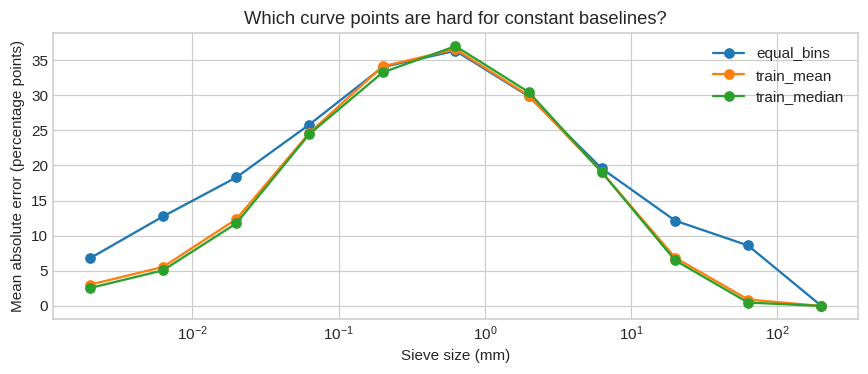

In [28]:
experimental_blended_score = (emd / 5 + worst_point_error) / 2
range_masks = {"fine_0.002_to_0.063": sieves[:-1] < 0.063,
               "sand_0.063_to_2": (sieves[:-1] >= 0.063) & (sieves[:-1] < 2),
               "coarse_2_to_200": sieves[:-1] >= 2}
diagnostic_rows, range_rows = [], []
for name, predictions in {**oof, "loo_median": loo_pred}.items():
    absolute = np.abs(y - predictions)
    true_d50 = np.array([grain_size(curve, 50) for curve in y])
    pred_d50 = np.array([grain_size(curve, 50) for curve in predictions])
    valid = np.isfinite(true_d50) & np.isfinite(pred_d50)
    diagnostic_rows.append({"baseline": name, "EMD": emd_per_sample(y, predictions).mean(),
                            "MAE_pp": absolute.mean(), "mean_worst_point_pp": absolute.max(axis=1).mean(),
                            "D50_abs_log10": np.abs(np.log10(true_d50[valid]/pred_d50[valid])).mean(),
                            "D50_pairs": valid.sum()})
    parts = []
    for name_range, mask in range_masks.items():
        contribution = (absolute[:, :-1][:, mask] * log_widths[mask]).sum(axis=1)
        parts.append(contribution)
        range_rows.append({"baseline": name, "range": name_range, "EMD_part": contribution.mean(),
                           "log_width": log_widths[mask].sum(), "normalized_error_pp": contribution.mean()/log_widths[mask].sum()})
    assert np.allclose(np.sum(parts, axis=0), emd_per_sample(y, predictions))
diagnostics = pd.DataFrame(diagnostic_rows)
range_errors = pd.DataFrame(range_rows)
display(diagnostics.round(3))
display(range_errors.query("baseline == 'train_median'").round(3))
print("Range EMD parts add to total EMD. Normalized errors compare ranges of different width.")
diagnostics.to_csv(EXTRA_DIR / "baseline_diagnostics.csv", index=False)
range_errors.to_csv(EXTRA_DIR / "range_errors.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.5))
for name, predictions in oof.items():
    ax.semilogx(sieves, np.abs(y-predictions).mean(axis=0), marker="o", label=name)
ax.set(xlabel="Sieve size (mm)", ylabel="Mean absolute error (percentage points)", title="Which curve points are hard for constant baselines?")
ax.legend()
fig.tight_layout()
plt.show()

### 10.2. Five hard samples

These are the five largest errors of the four-fold median baseline.
The photos are here to help us ask questions, not to claim that the baseline uses images.
The true curve is blue. The OOF curve is orange.

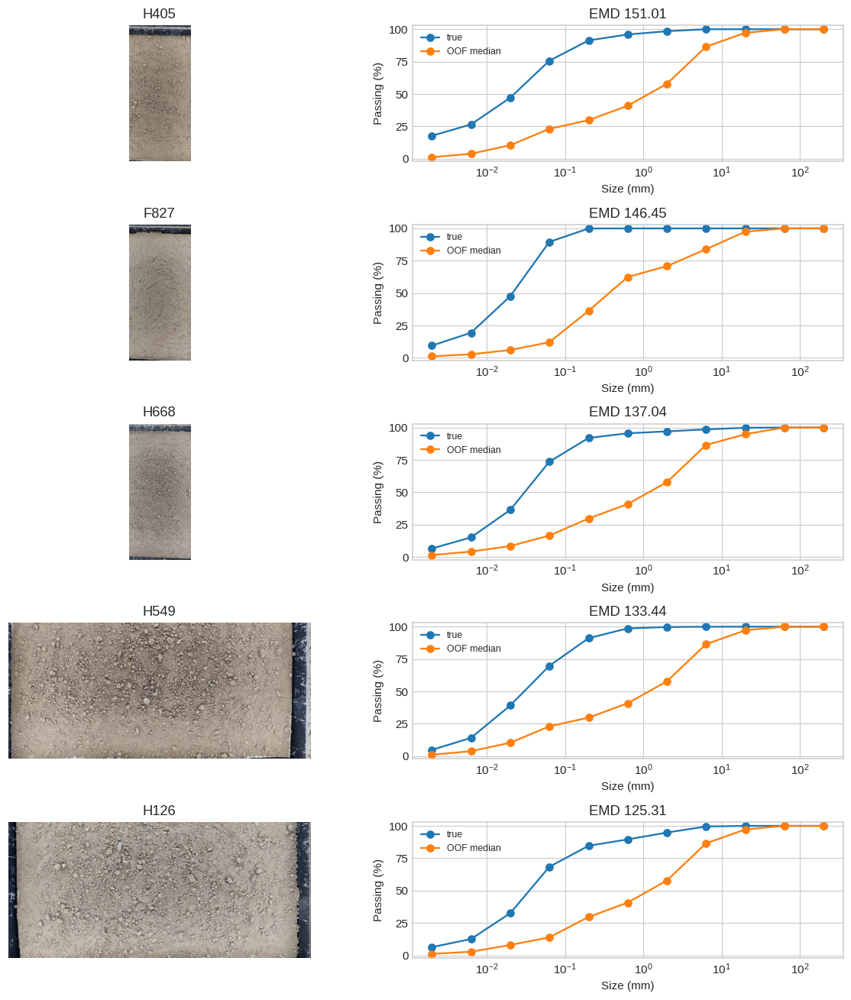

In [29]:
median_errors = emd_per_sample(y, oof["train_median"])
worst_indices = np.argsort(median_errors)[-5:][::-1]
fig, axes = plt.subplots(5, 2, figsize=(11, 12))
for axes_row, index in zip(axes, worst_indices):
    sample_id = labels.loc[index, "sample_id"]
    path = photos.query("split == 'train' and sample_id == @sample_id").iloc[0].path
    with Image.open(path) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")
        image.thumbnail((640, 420))
    axes_row[0].imshow(image)
    axes_row[0].axis("off")
    axes_row[0].set_title(sample_id)
    axes_row[1].semilogx(sieves, y[index], marker="o", label="true")
    axes_row[1].semilogx(sieves, oof["train_median"][index], marker="o", label="OOF median")
    axes_row[1].set(title=f"EMD {median_errors[index]:.2f}", xlabel="Size (mm)", ylabel="Passing (%)", ylim=(-2, 103))
    axes_row[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 11. Try tiles with the same size in mm

We start with 64 mm tiles and save them as 224 x 224 pixels.
This gives 3.5 pixels per mm for every camera. It covers more coarse grains than a small crop.
Very small grains are still too small to see. We must test other tile sizes later.

We cache three tiles from each train photo. We do not use test photos here.
Tiles still have one sample label. They are not new samples.

Cached tiles: 381 | Train photos: 127
Physical side range (mm): 63.9 to 64.02


,min_native_ppm
split,
test,13.94
train,4.55


Output pixels per mm: 3.5


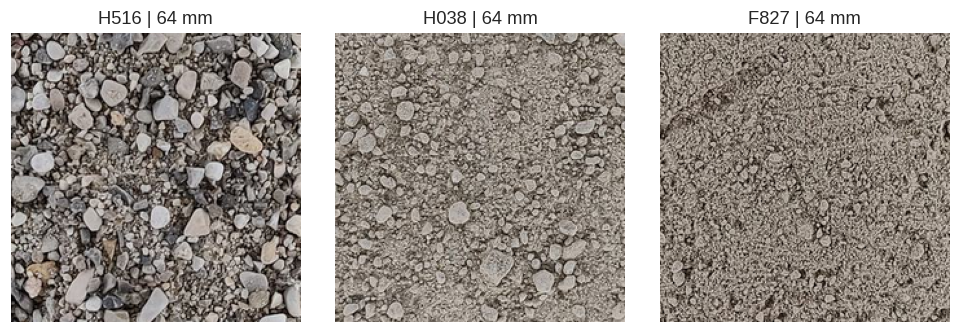

In [30]:
TILE_MM = 64
TILE_PX = 224
CACHE_DIR = WORK_DIR / f"tiles_{TILE_MM}mm_{TILE_PX}px"
CACHE_DIR.mkdir(exist_ok=True)
centres = [(0.4, 0.5), (0.5, 0.5), (0.6, 0.5)]

tile_rows = []
for row in train_photos.itertuples(index=False):
    crop_px = round(TILE_MM * row.ppm_est)
    with Image.open(row.path) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")
        assert crop_px <= min(image.size)
        for tile_id, (cx, cy) in enumerate(centres):
            left = round(cx * image.width - crop_px / 2)
            top = round(cy * image.height - crop_px / 2)
            box = (left, top, left + crop_px, top + crop_px)
            assert left >= 0 and top >= 0 and box[2] <= image.width and box[3] <= image.height
            tile_path = CACHE_DIR / f"{Path(row.photo).stem}_{tile_id}.png"
            if not tile_path.exists():
                tile = image.crop(box).resize((TILE_PX, TILE_PX), Image.Resampling.LANCZOS)
                tile.save(tile_path)
            tile_rows.append({"sample_id": row.sample_id, "photo": row.photo, "fold": row.fold,
                              "tile_id": tile_id, "tile_path": str(tile_path), "crop_px": crop_px,
                              "ppm_est": row.ppm_est, "actual_tile_mm": crop_px / row.ppm_est})

tiles = pd.DataFrame(tile_rows)
assert tiles.groupby("sample_id").fold.nunique().eq(1).all()
tiles.to_csv(WORK_DIR / "tile_manifest.csv", index=False)
print("Cached tiles:", len(tiles), "| Train photos:", len(train_photos))
print("Physical side range (mm):", round(tiles.actual_tile_mm.min(), 2), "to", round(tiles.actual_tile_mm.max(), 2))
display(photos.groupby("split").ppm_est.min().to_frame("min_native_ppm").round(2))
print("Output pixels per mm:", TILE_PX / TILE_MM)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, sample_id in zip(axes, example_ids):
    row = tiles.query("sample_id == @sample_id and tile_id == 1").iloc[0]
    with Image.open(row.tile_path) as image:
        ax.imshow(image)
    ax.set_title(sample_id + " | 64 mm")
    ax.axis("off")
fig.tight_layout()
plt.show()

### 11.1. Keep the native crop too

The old 64 mm / 224 px tiles stay unchanged.
A native crop has no resize. Its pixel size depends on the camera, so a model needs a way to handle that.
224 px is a model input choice, not a rule of physics.
Whole photos have different shapes and can use much more memory.
Tiles give smaller inputs with the same estimated view size and less tray background.
But one tile can miss a large stone. Its local surface may not match the full sample mass.
This is why we keep several areas and average photo and sample curves.

Now we compare 32, 64, and 128 mm views. We also try 224, 288, and 384 px for 64 mm.
This is a pixel and image check. We have not trained models to compare their CV scores.

,tile_mm,output_px,split,min_crop_px,max_crop_px,ideal_output_ppm,photos_upscaled_pct,three_px_mm_output
0,32,144,train,146.0,399.0,4.50,0.000,0.667
1,32,144,test,446.0,625.0,4.50,0.000,0.667
2,32,224,train,146.0,399.0,7.00,97.638,0.429
3,32,224,test,446.0,625.0,7.00,0.000,0.429
4,64,224,train,291.0,798.0,3.50,0.000,0.857
5,64,224,test,892.0,1250.0,3.50,0.000,0.857
6,64,288,train,291.0,798.0,4.50,0.000,0.667
7,64,288,test,892.0,1250.0,4.50,0.000,0.667
8,64,384,train,291.0,798.0,6.00,97.638,0.500
9,64,384,test,892.0,1250.0,6.00,0.000,0.500


New central views cached: 889
Old 64 mm / 224 px tiles are still in: /kaggle/working/soil_eda/tiles_64mm_224px


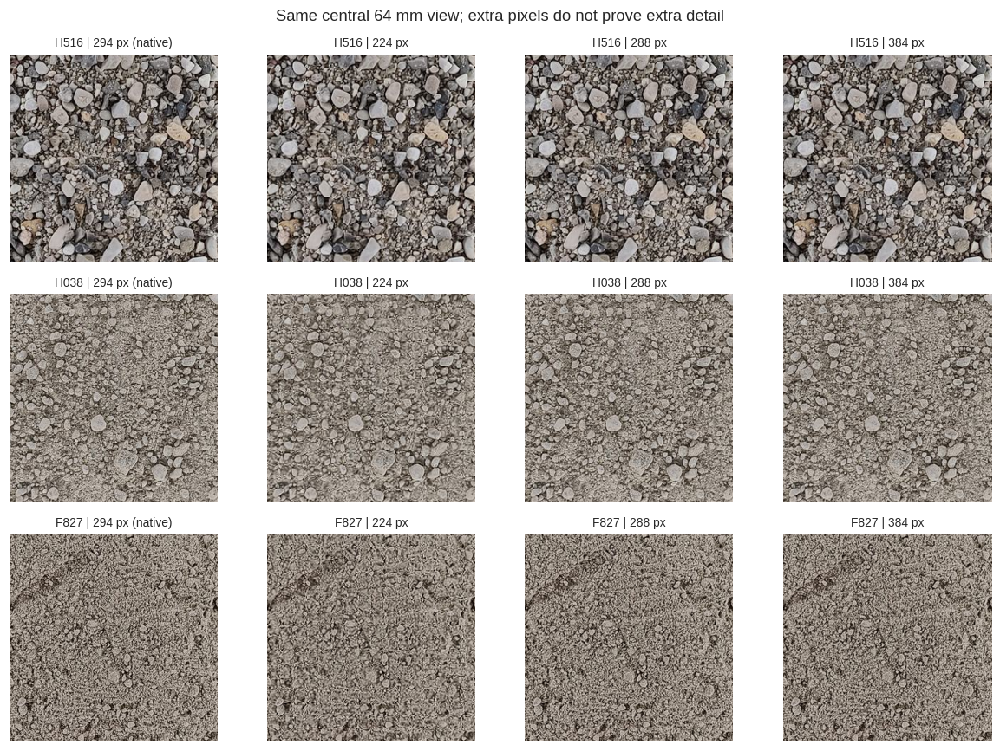

In [31]:
configs = [(32, 144), (32, 224), (64, 224), (64, 288), (64, 384), (128, 288)]
config_rows = []
for tile_mm, output_px in configs:
    crop_px = np.rint(tile_mm * photos.ppm_est)
    output_ppm = output_px * photos.ppm_est / crop_px
    for split in ["train", "test"]:
        take = photos.split.eq(split)
        config_rows.append({"tile_mm": tile_mm, "output_px": output_px, "split": split,
                            "min_crop_px": crop_px[take].min(), "max_crop_px": crop_px[take].max(),
                            "ideal_output_ppm": output_px/tile_mm,
                            "photos_upscaled_pct": 100*(output_px > crop_px[take]).mean(),
                            "three_px_mm_output": 3/(output_px/tile_mm)})
config_table = pd.DataFrame(config_rows)
display(config_table.round(3))
config_table.to_csv(EXTRA_DIR / "tile_config_comparison.csv", index=False)

# Cache one central view per train photo for each setting, plus native 64 mm crops.
new_tile_rows = []
for row in train_photos.itertuples(index=False):
    with Image.open(row.path) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")
        for tile_mm, output_px in configs + [(64, None)]:
            crop_px = round(tile_mm * row.ppm_est)
            left, top = (image.width-crop_px)//2, (image.height-crop_px)//2
            assert left >= 0 and top >= 0
            side = output_px if output_px is not None else crop_px
            setting = f"{tile_mm}mm_{output_px}px" if output_px is not None else "64mm_native"
            folder = EXTRA_DIR / ("tiles_" + setting)
            folder.mkdir(exist_ok=True)
            tile_path = folder / (Path(row.photo).stem + ".png")
            if not tile_path.exists():
                crop = image.crop((left, top, left+crop_px, top+crop_px))
                if output_px is not None:
                    crop = crop.resize((output_px, output_px), Image.Resampling.LANCZOS)
                crop.save(tile_path)
            new_tile_rows.append({"sample_id": row.sample_id, "photo": row.photo, "device": row.device,
                                  "fold": row.fold, "setting": setting, "tile_path": str(tile_path),
                                  "left": left, "top": top, "crop_px": crop_px, "output_px": side,
                                  "tile_mm_est": crop_px/row.ppm_est,
                                  "output_ppm_est": side*row.ppm_est/crop_px,
                                  "native_ppm_est": row.ppm_est, "upscaled": side > crop_px})
new_tiles = pd.DataFrame(new_tile_rows)
assert new_tiles.groupby("sample_id").fold.nunique().eq(1).all()
new_tiles.to_csv(EXTRA_DIR / "tile_manifest_extended.csv", index=False)
print("New central views cached:", len(new_tiles))
print("Old 64 mm / 224 px tiles are still in:", CACHE_DIR)

fig, axes = plt.subplots(3, 4, figsize=(11, 8))
settings = ["64mm_native", "64mm_224px", "64mm_288px", "64mm_384px"]
for i, sample_id in enumerate(example_ids):
    photo = train_photos.query("sample_id == @sample_id").iloc[0].photo
    for j, setting in enumerate(settings):
        tile_row = new_tiles.query("photo == @photo and setting == @setting").iloc[0]
        with Image.open(tile_row.tile_path) as image:
            axes[i,j].imshow(image)
        axes[i,j].set_title(sample_id + f" | {tile_row.output_px} px" + (" (native)" if j==0 else ""), fontsize=9)
        axes[i,j].axis("off")
fig.suptitle("Same central 64 mm view; extra pixels do not prove extra detail")
fig.tight_layout()
plt.show()

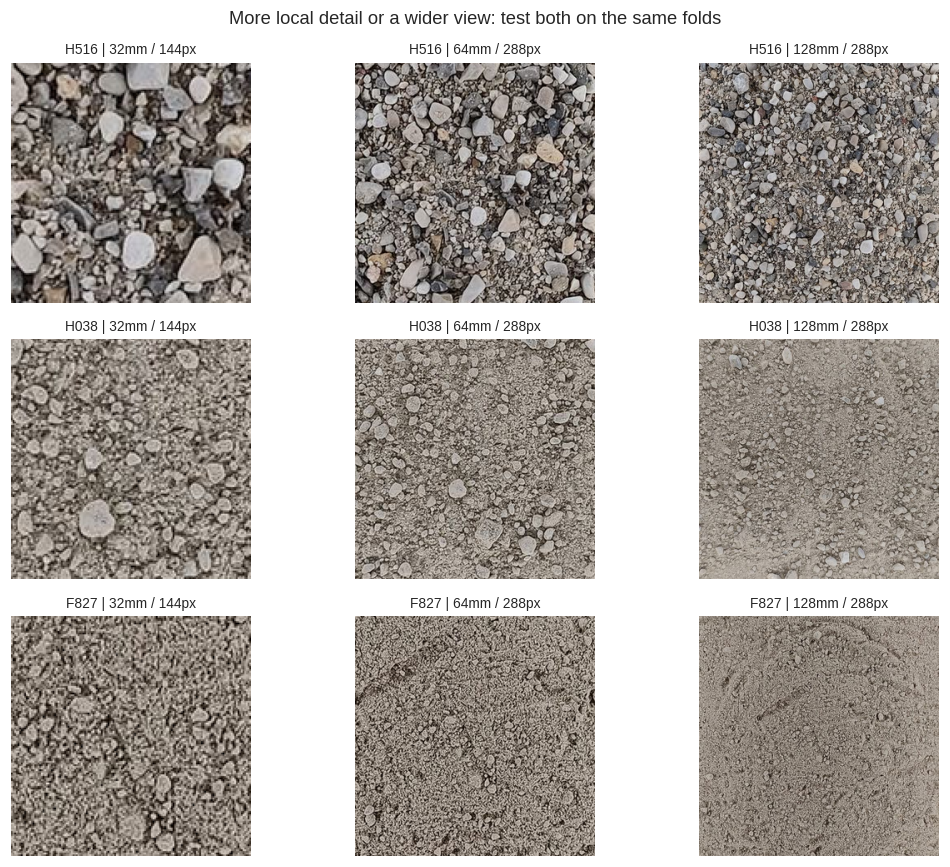

native_ppm  output_ppm  detail_ppm_guide  \
setting     device                                                              
128mm_288px Motorola Edge                 4.597       2.251             2.251   
            Motorola Edge 60 Fusion      12.465       2.249             2.249   
            Samsung A52                   4.554       2.250             2.250   
32mm_144px  Motorola Edge                 4.597       4.503             4.503   
            Motorola Edge 60 Fusion      12.465       4.499             4.499   
            Samsung A52                   4.554       4.492             4.492   
32mm_224px  Motorola Edge                 4.597       7.005             4.597   
            Motorola Edge 60 Fusion      12.465       6.998             6.998   
            Samsung A52                   4.554       6.987             4.554   
64mm_224px  Motorola Edge                 4.597       3.502             3.502   
            Motorola Edge 60 Fusion      12.465       3.499             3.499   
            Samsung A52                   4.554       3.505             3.505   
64mm_288px  Motorola Edge                 4.597       4.503             4.503   
            Motorola Edge 60 Fusion      12.465       4.499             4.499   
            Samsung A52                   4.554       4.507             4.507   
64mm_384px  Motorola Edge                 4.597       6.004             4.597   
            Motorola Edge 60 Fusion      12.465       5.998             5.998   
            Samsung A52                   4.554       6.009             4.554   
64mm_native Motorola Edge                 4.597       4.597             4.597   
            Motorola Edge 60 Fusion      12.465      12.465            12.465   
            Samsung A52                   4.554       4.554             4.554   

                                     upscaled_photos  \
setting     device                                     
128mm_288px Motorola Edge                          0   
            Motorola Edge 60 Fusion                0   
            Samsung A52                            0   
32mm_144px  Motorola Edge                          0   
            Motorola Edge 60 Fusion                0   
            Samsung A52                            0   
32mm_224px  Motorola Edge                         69   
            Motorola Edge 60 Fusion                0   
            Samsung A52                           55   
64mm_224px  Motorola Edge                          0   
            Motorola Edge 60 Fusion                0   
            Samsung A52                            0   
64mm_288px  Motorola Edge                          0   
            Motorola Edge 60 Fusion                0   
            Samsung A52                            0   
64mm_384px  Motorola Edge                         69   
            Motorola Edge 60 Fusion                0   
            Samsung A52                           55   
64mm_native Motorola Edge                          0   
            Motorola Edge 60 Fusion                0   
            Samsung A52                            0   

                                     three_pixel_grain_mm_guide  
setting     device                                               
128mm_288px Motorola Edge                                 1.332  
            Motorola Edge 60 Fusion                       1.334  
            Samsung A52                                   1.334  
32mm_144px  Motorola Edge                                 0.666  
            Motorola Edge 60 Fusion                       0.667  
            Samsung A52                                   0.668  
32mm_224px  Motorola Edge                                 0.653  
            Motorola Edge 60 Fusion                       0.429  
            Samsung A52                                   0.659  
64mm_224px  Motorola Edge                                 0.857  
            Motorola Edge 60 Fusion                       0.857  
            Samsung A52   

This guide ignores blur, lens quality, light, and depth. It is not a proven resolution limit.


In [32]:
fig, axes = plt.subplots(3, 3, figsize=(10, 8))
settings = ["32mm_144px", "64mm_288px", "128mm_288px"]
for i, sample_id in enumerate(example_ids):
    photo = train_photos.query("sample_id == @sample_id").iloc[0].photo
    for j, setting in enumerate(settings):
        tile_row = new_tiles.query("photo == @photo and setting == @setting").iloc[0]
        with Image.open(tile_row.tile_path) as image:
            axes[i,j].imshow(image)
        axes[i,j].set_title(sample_id + " | " + setting.replace("_", " / "), fontsize=9)
        axes[i,j].axis("off")
fig.suptitle("More local detail or a wider view: test both on the same folds")
fig.tight_layout()
plt.show()

# Do not count interpolated pixels as new image information.
new_tiles["detail_ppm_guide"] = np.minimum(new_tiles.output_ppm_est, new_tiles.native_ppm_est)
detail_guide = new_tiles.groupby(["setting", "device"]).agg(
    native_ppm=("native_ppm_est", "median"), output_ppm=("output_ppm_est", "median"),
    detail_ppm_guide=("detail_ppm_guide", "median"), upscaled_photos=("upscaled", "sum")
)
detail_guide["three_pixel_grain_mm_guide"] = 3/detail_guide.detail_ppm_guide
display(detail_guide.round(3))
print("This guide ignores blur, lens quality, light, and depth. It is not a proven resolution limit.")

## 12. Check tile to sample scoring

First, average tile curves for each photo. Then, average photo curves for each soil sample.
This gives each photo the same weight, even if tile counts change.
Here we use the fold median as a fake tile prediction. This only checks the data flow.

In [33]:
tile_predictions = tiles[["sample_id", "photo", "fold"]].copy()
for column in targets:
    tile_predictions[column] = 0.0
for fold in range(N_FOLDS):
    curve = np.median(y[fold_id != fold], axis=0)
    tile_predictions.loc[tile_predictions.fold == fold, targets] = curve

photo_predictions = tile_predictions.groupby(["sample_id", "photo"])[targets].mean()
sample_predictions = photo_predictions.groupby("sample_id")[targets].mean().reindex(labels.sample_id)
assert np.allclose(sample_predictions.to_numpy(), oof["train_median"])
print("Tile -> photo -> sample check passed.")
print(f"Sample-level EMD: {emd_per_sample(y, sample_predictions.to_numpy()).mean():.3f}")
print("Files saved in:", WORK_DIR)

Tile -> photo -> sample check passed.
Sample-level EMD: 85.213
Files saved in: /kaggle/working/soil_eda


### 12.1. Camera coverage and simple image checks

We compare the same soils across cameras. The matrix counts photos, not independent samples.
There are no iPhone train photos. This is a train/test camera change.

We use brightness and edge strength on the same 64 mm / 288 px view.
They are simple image checks, not learned features or a soil model.
Differences can come from lighting, focus, image resize, and camera angle.

device,Motorola Edge,Motorola Edge 60 Fusion,Samsung A52
sample_id,,,
F827,2,0,3
G190,2,0,3
H030,4,0,3
H037,3,0,3
H038,3,0,5
H126,3,0,1
H181,4,0,2
H183,4,0,3
H366,4,0,0


Train cameras: Motorola Edge, Motorola Edge 60 Fusion, Samsung A52
Test cameras: iPhone 14, iPhone 16


,brightness,contrast,edge_strength
device,,,
Motorola Edge,0.480,0.197,10385.704
Motorola Edge 60 Fusion,0.630,0.186,10563.175
Samsung A52,0.514,0.155,6765.856


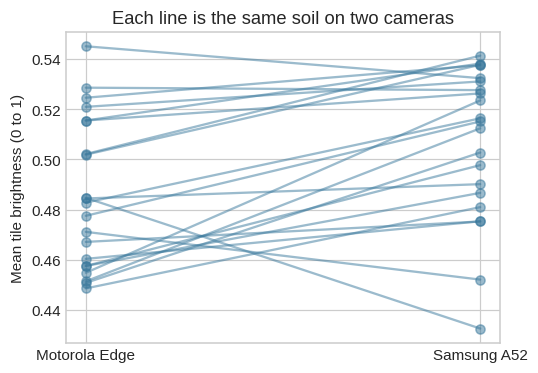

Paired soils: 21
Median absolute brightness gap: 0.029


In [34]:
camera_coverage = pd.crosstab(train_photos.sample_id, train_photos.device)
display(camera_coverage)
camera_coverage.to_csv(EXTRA_DIR / "camera_coverage.csv")
print("Train cameras:", ", ".join(sorted(train_photos.device.unique())))
print("Test cameras:", ", ".join(sorted(photos.query("split == 'test'").device.unique())))

feature_rows = []
for row in new_tiles.query("setting == '64mm_288px'").itertuples(index=False):
    with Image.open(row.tile_path) as image:
        gray = np.asarray(image.convert("L"), dtype=np.uint8)
    feature_rows.append({"sample_id": row.sample_id, "device": row.device, "photo": row.photo,
                         "brightness": gray.mean()/255, "contrast": gray.std()/255,
                         "edge_strength": cv2.Laplacian(gray, cv2.CV_64F).var()})
image_checks = pd.DataFrame(feature_rows)
by_sample_camera = image_checks.groupby(["sample_id", "device"])[["brightness", "contrast", "edge_strength"]].mean()
display(by_sample_camera.groupby("device").median().round(3))
paired_brightness = by_sample_camera.brightness.unstack("device").reindex(columns=["Motorola Edge", "Samsung A52"]).dropna()
fig, ax = plt.subplots(figsize=(5, 3.5))
for _, row in paired_brightness.iterrows():
    ax.plot([0, 1], row.to_numpy(), marker="o", color="#39789c", alpha=0.5)
ax.set_xticks([0, 1], paired_brightness.columns)
ax.set(ylabel="Mean tile brightness (0 to 1)", title="Each line is the same soil on two cameras")
fig.tight_layout()
plt.show()
print("Paired soils:", len(paired_brightness))
print("Median absolute brightness gap:", round(paired_brightness.diff(axis=1).iloc[:,1].abs().median(), 3))
image_checks.to_csv(EXTRA_DIR / "camera_image_checks.csv", index=False)

## Main points

- Train has 24 soil samples and 127 photos. Test has 10 samples and 35 photos.
- A random photo split shares 19 samples between train and validation.
- Test uses iPhones. Train uses Motorola and Samsung. Most train photos are about 1 to 2 MP.
- The PPM resize check is important. We must confirm the no-crop assumption.
- Photos show black tray edges and bright light spots. These can give a model false clues.
- Use the same sample folds and score one curve per sample.
- The test CSV has empty target values. They are not soil labels.
- The train-median baseline has OOF EMD 85.213. A 2x size shift gives mean EMD 30.566.
- A good next test is 32, 64, and 128 mm tiles on the same folds.

AI helped write and check this EDA. Read and check the code before using it in the full lab.

## New findings and limits

- We checked 293 photo pairs. 133 pass the stronger geometry check.
- For 67 Motorola/Samsung pairs, the same-point length ratio has median 1.012. Relative scale is close, but absolute scale is still unknown.
- Most train photos have no camera EXIF. Missing EXIF is not proof of a crop or a resize.
- Two PCA parts keep 97.63% of label variance. This is label structure, not an image prediction score.
- Four-fold median EMD stays 85.213. LOOCV median EMD is 97.248. The split choice matters on this small set.
- 64 mm / 288 px needs no upscaling in train. 64 mm / 384 px upscales 97.64% of train photos.

- File resize and camera zoom are different. We cannot undo lost detail by making a photo bigger.
- The matching and EXIF checks test possible problems. They do not prove that PPM is correct.
- We need a known physical length or the original files to check absolute PPM.
- The old blended score stays as an experiment. Official EMD remains the main score.
- 64 mm / 288 px keeps more source pixels than 224 px for most train photos. It is a setting to test, not a proven winner.
- Compare native, small-view, and wide-view crops on the same folds before choosing a model input.

A photo shows the top surface. Labels measure mass from the full soil sample.
Small particles can be hidden. Light, water, grain colour, and camera angle can change the photo.
We may learn useful texture clues, but a surface photo may not fully identify the lab curve.
A model error alone cannot tell us whether the model or the image information is the main limit.

For a later image encoder, compare same-soil and different-soil features across cameras.
That test needs image features; this CPU EDA does not claim to have run it.

## Final checks before an image model

We keep all earlier results. These four small checks help us read the next model scores.
The original four folds stay fixed. We do not choose a new seed from the scores below.

### A. Does the baseline score depend on the split?

We try 20 seeds with four folds each. Each seed gives one OOF curve per soil sample.
We compare the mean score over all 24 samples, not 80 separate fold scores.
This shows split sensitivity. It is not a confidence interval or a test of new soils.

,count,mean,std,min,max
baseline,,,,,
equal_bins,20,102.023,0.000,102.023,102.023
train_mean,20,87.075,0.739,86.396,89.159
train_median,20,87.862,2.458,85.213,95.657


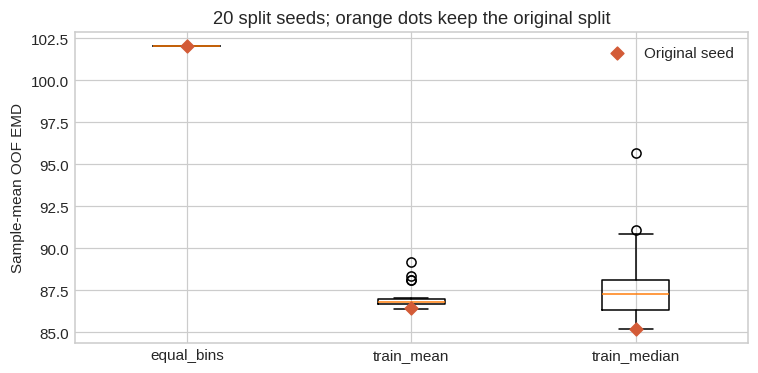

The original folds and OOF predictions have not changed.


In [35]:
repeat_rows, repeat_fold_rows = [], []
original_fold_ids = fold_id.copy()
for seed in range(SEED, SEED + 20):
    splitter_check = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    repeated_pred = {name: np.zeros_like(y) for name in oof}
    seed_folds = np.full(len(y), -1)
    for fold, (train_index, valid_index) in enumerate(splitter_check.split(y, labels.soil_group)):
        seed_folds[valid_index] = fold
        repeated_pred["equal_bins"][valid_index] = np.arange(1, 12) / 11 * 100
        repeated_pred["train_mean"][valid_index] = y[train_index].mean(axis=0)
        repeated_pred["train_median"][valid_index] = np.median(y[train_index], axis=0)
    if seed == SEED:
        assert np.array_equal(seed_folds, original_fold_ids)
        for name in oof:
            assert np.allclose(repeated_pred[name], oof[name])
    for name, predictions in repeated_pred.items():
        repeat_rows.append({"seed": seed, "baseline": name, "sample_mean_EMD": emd_per_sample(y, predictions).mean()})
    for sample_id, fold in zip(labels.sample_id, seed_folds):
        repeat_fold_rows.append({"seed": seed, "sample_id": sample_id, "fold": fold})

repeated_scores = pd.DataFrame(repeat_rows)
display(repeated_scores.groupby("baseline").sample_mean_EMD.agg(["count", "mean", "std", "min", "max"]).round(3))
repeated_scores.to_csv(EXTRA_DIR / "repeated_baseline_scores.csv", index=False)
pd.DataFrame(repeat_fold_rows).to_csv(EXTRA_DIR / "repeated_folds_audit.csv", index=False)
assert np.array_equal(fold_id, original_fold_ids)

names = ["equal_bins", "train_mean", "train_median"]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot([repeated_scores.query("baseline == @name").sample_mean_EMD for name in names], tick_labels=names)
for position, name in enumerate(names, start=1):
    value = repeated_scores.query("baseline == @name and seed == @SEED").sample_mean_EMD.iloc[0]
    ax.scatter(position, value, color="#d35b37", marker="D", s=35, zorder=3, label="Original seed" if position == 1 else None)
ax.set(ylabel="Sample-mean OOF EMD", title="20 split seeds; orange dots keep the original split")
ax.legend()
fig.tight_layout()
plt.show()
print("The original folds and OOF predictions have not changed.")

### B. Which soil group is hard?

We use the original four-fold OOF curves. Each sample has the same weight inside its group.
The overall score still weights every sample equally. Groups have different sample counts.
A macro score gives each group one equal vote. It is a separate check, not the Kaggle score.

In [36]:
group_rows = []
for name, predictions in oof.items():
    sample_error = emd_per_sample(y, predictions)
    for soil_group in ["fine", "sand", "gravel"]:
        take = labels.soil_group.eq(soil_group).to_numpy()
        group_rows.append({"baseline": name, "soil_group": soil_group, "samples": int(take.sum()),
                           "mean_EMD": sample_error[take].mean(), "median_EMD": np.median(sample_error[take])})
soil_group_scores = pd.DataFrame(group_rows)
display(soil_group_scores.round(3))

group_summary = soil_group_scores.groupby("baseline").apply(
    lambda group: pd.Series({"sample_weighted_EMD": np.average(group.mean_EMD, weights=group.samples),
                             "macro_group_EMD": group.mean_EMD.mean()}), include_groups=False
)
for name, predictions in oof.items():
    assert np.isclose(group_summary.loc[name, "sample_weighted_EMD"], emd_per_sample(y, predictions).mean())
display(group_summary.round(3))
soil_group_scores.to_csv(EXTRA_DIR / "oof_errors_by_soil_group.csv", index=False)
print("These are image-free baselines. Group gaps do not show how a future image model will behave.")

,baseline,soil_group,samples,mean_EMD,median_EMD
0,equal_bins,fine,7,112.930,115.650
1,equal_bins,sand,6,92.833,102.057
2,equal_bins,gravel,11,100.095,103.496
3,train_mean,fine,7,107.005,110.778
4,train_mean,sand,6,67.329,73.536
5,train_mean,gravel,11,83.824,83.909
6,train_median,fine,7,127.148,133.440
7,train_median,sand,6,78.206,84.384
8,train_median,gravel,11,62.350,62.543


,sample_weighted_EMD,macro_group_EMD
baseline,,
equal_bins,102.023,101.953
train_mean,86.461,86.052
train_median,85.213,89.235


These are image-free baselines. Group gaps do not show how a future image model will behave.


### C. Give each soil one vote in the scale check

The earlier 67 cross-camera pairs share photos and soil samples.
We now take one median length ratio for each soil. Bars show the range of its photo-pair ratios.
They are not confidence intervals. This check covers matched Motorola/Samsung patches only.
A ratio near 1 means relative agreement. It still cannot prove absolute PPM.

,photo_pairs,median_ratio,min_ratio,max_ratio,median_gap_pct
sample_id,,,,,
F827,5,1.009,1.009,1.012,0.868
G190,2,1.016,1.014,1.017,1.590
H030,3,1.011,1.007,1.016,1.132
H037,2,1.014,1.013,1.014,1.363
H038,5,1.013,1.007,1.015,1.251
H126,3,1.012,1.006,1.037,1.232
H181,2,1.011,1.010,1.012,1.079
H183,2,1.010,1.009,1.012,1.047
H367,1,1.016,1.016,1.016,1.580


Matched photo pairs: 67 | Soil samples with one vote each: 21
Pair-weighted median ratio: 1.0123
Median of soil-level ratios: 1.0123


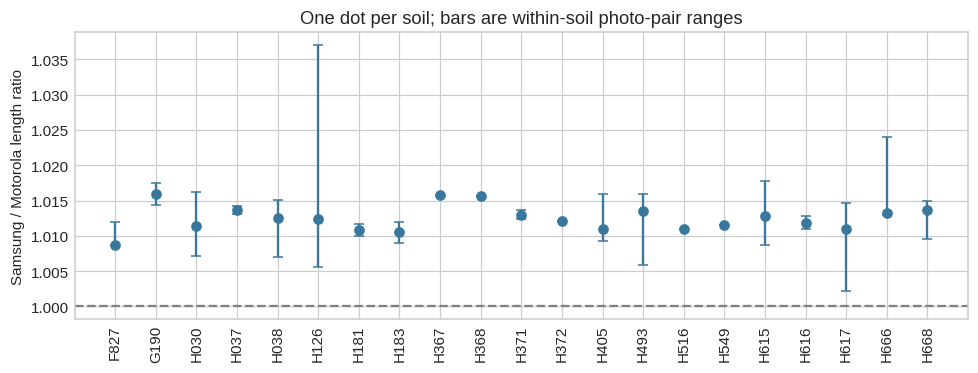

In [37]:
matched_cameras = strong_pairs.query("device_a == 'Motorola Edge' and device_b == 'Samsung A52'")
sample_scale = matched_cameras.groupby("sample_id").segment_ratio_b_to_a.agg(
    photo_pairs="size", median_ratio="median", min_ratio="min", max_ratio="max"
)
assert len(sample_scale) > 0
sample_scale["median_gap_pct"] = 100 * (sample_scale.median_ratio - 1)
display(sample_scale.round(3))
print("Matched photo pairs:", len(matched_cameras), "| Soil samples with one vote each:", len(sample_scale))
print("Pair-weighted median ratio:", round(matched_cameras.segment_ratio_b_to_a.median(), 4))
print("Median of soil-level ratios:", round(sample_scale.median_ratio.median(), 4))
sample_scale.to_csv(EXTRA_DIR / "relative_scale_by_sample.csv")

fig, ax = plt.subplots(figsize=(9, 3.5))
ratios = sample_scale.sort_index()
ax.errorbar(np.arange(len(ratios)), ratios.median_ratio,
            yerr=[ratios.median_ratio-ratios.min_ratio, ratios.max_ratio-ratios.median_ratio],
            fmt="o", capsize=3, color="#39789c")
ax.axhline(1, color="gray", linestyle="--")
ax.set_xticks(np.arange(len(ratios)), ratios.index, rotation=90)
ax.set(ylabel="Samsung / Motorola length ratio", title="One dot per soil; bars are within-soil photo-pair ranges")
fig.tight_layout()
plt.show()

### D. What do the first two PCA parts change?

We show the mean curve plus or minus two standard deviations along one PCA direction.
These are raw math curves. They are not real samples or confidence limits.
Values can go below 0, above 100, or go down. The table checks these problems.
PCA uses all train labels here for a plot only. A model must fit it inside each train fold.

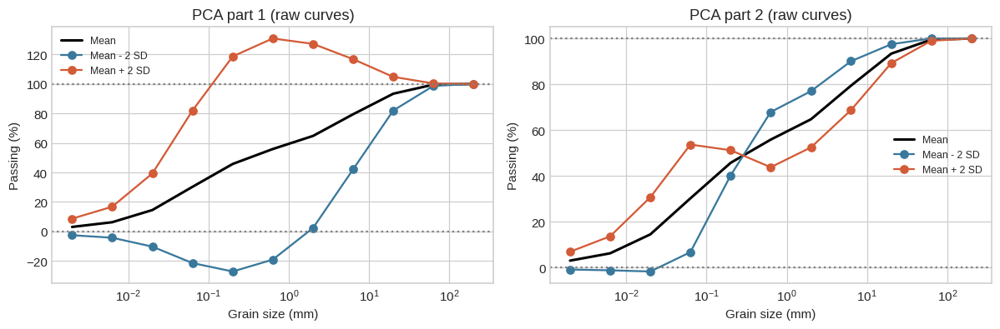

,component,curve,min_pct,max_pct,goes_down,ends_at_100
0,1,Mean - 2 SD,-27.160,100.000,True,True
1,1,Mean + 2 SD,8.672,130.850,True,True
2,2,Mean - 2 SD,-1.692,100.025,True,True
3,2,Mean + 2 SD,6.934,100.000,True,True


In [38]:
pca_view = PCA(n_components=2).fit(y)
pca_curve_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
for component, ax in enumerate(axes):
    change = 2 * np.sqrt(pca_view.explained_variance_[component]) * pca_view.components_[component]
    ax.semilogx(sieves, pca_view.mean_, color="black", linewidth=2, label="Mean")
    for sign, color in [(-1, "#39789c"), (1, "#d35b37")]:
        curve = pca_view.mean_ + sign * change
        label = "Mean - 2 SD" if sign < 0 else "Mean + 2 SD"
        ax.semilogx(sieves, curve, marker="o", color=color, label=label)
        pca_curve_rows.append({"component": component+1, "curve": label, "min_pct": curve.min(), "max_pct": curve.max(),
                               "goes_down": bool((np.diff(curve) < -1e-6).any()), "ends_at_100": bool(np.isclose(curve[-1], 100))})
    ax.axhline(0, color="gray", linestyle=":")
    ax.axhline(100, color="gray", linestyle=":")
    ax.set(xlabel="Grain size (mm)", ylabel="Passing (%)", title=f"PCA part {component+1} (raw curves)")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
pca_curve_checks = pd.DataFrame(pca_curve_rows)
display(pca_curve_checks.round(3))
pca_curve_checks.to_csv(EXTRA_DIR / "pca_direction_checks.csv", index=False)

## Ready for the next step

On 20 splits, mean EMD is 87.075 for train mean and 87.862 for train median.
The old median score, 85.213, is the lowest of these 20 splits. Its small lead is not stable.
On the original folds, median error is 127.148 for fine soils and 62.350 for gravel soils.
These are baseline results, not limits for an image model.

Keep the original four folds. Start an image baseline with 64 mm / 288 px views.
Compare with both old baselines. Check sample-level EMD and each soil group.
Use the repeated-seed results to judge small score changes. Do not pick the best seed.
The soil-level scale ratio is still about 1.012, but absolute PPM remains unknown.
A PCA output needs a valid, non-decreasing curve that ends at 100.
